# Detección de errores de técnica en el remo con barra mediante Deep Learning

### Notebook 1 de 2: Entrenamiento y evaluación

Matías Martínez Moreno

12 de noviembre de 2026

---

## 1. El problema

El remo con barra es un ejercicio popular de espalda: se inclina el torso y se jala la barra hacia el abdomen. Con mala técnica se carga la zona lumbar y cuesta notarlo mientras se levanta. El notebook detecta en fotos dos errores definidos en Fitness-AQA (Parmar et al., 2022), repeticiones de Instagram y YouTube etiquetadas por entrenadores:

| Error | Lo correcto | El error |
|---|---|---|
| Lumbar | espalda baja neutra | curvatura excesiva de la zona lumbar |
| Torso | entre la paralela al piso y unos 45° | muy erguido (menos de 45°) o por debajo de la paralela |

## 2. Objetivos

General: Implementar, adaptar y evaluar CNN preentrenadas en ImageNet para detectar estos errores en fotos de Fitness-AQA y comprobar si el desempeño se mantiene con videos propios.

1. Comparar ResNet-18, ResNet-50 y ConvNeXt-S con 3 estrategias de transfer learning y 3 semillas, ajustar hiperparámetros, armar un ensamble de 5 semillas y medir el aporte de ImageNet (fases 1 a 4).
2. Evaluar una sola vez en la prueba oficial (AP, F1, precisión y recall con IC 95 %) y mirar Grad-CAM (fases 5 y 6).
3. Probar con videos propios y con cambios de luz, nitidez y giro (notebook 2).

Ejecución: Kaggle con 2 GPU T4 y el dataset privado de Fitness-AQA

In [1]:
# ============================================================
# Configuración de la corrida
# ============================================================
COMPROBAR_PESOS = True

In [2]:
%pip uninstall -y -q onnxruntime
%pip install -q --no-deps rtmlib==0.0.16
%pip install -q onnxruntime-gpu==1.23.2

In [3]:
# ============================================================
# Librerías, configuración y utilidades
# ============================================================
import os, sys, json, time, math, shutil, zipfile, threading, warnings, html, uuid, platform, pickle
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F, timm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from sklearn.metrics import average_precision_score, precision_recall_curve

warnings.filterwarnings('ignore'); cv2.setNumThreads(1)
T0 = time.time()
PRUEBA = os.environ.get('FAQA_PRUEBA') == '1'          # prueba local de la lógica: datos sintéticos, pose falsa y redes diminutas
if PRUEBA:
    torch.set_num_threads(2)
ENTRADA = Path(os.environ.get('FAQA_INPUT', '/kaggle/input'))
WORK = Path(os.environ.get('FAQA_WORK', '/tmp/remo')); OUT = Path(os.environ.get('FAQA_OUT', '/kaggle/working/outputs'))
for d in ['figuras', 'tablas']:
    (OUT / d).mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
DEVS = [f'cuda:{i}' for i in range(torch.cuda.device_count())] or ['cpu']
ERR = ['lumbar', 'torso']; NOMBRE_ERR = {'lumbar': 'Lumbar', 'torso': 'Torso'}
NOTAS, TIEMPOS = [], {}
BOOT = 20 if PRUEBA else 1000                          # remuestreos del bootstrap por clip
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold'})
ESQUELETO = [(5, 7), (7, 9), (6, 8), (8, 10), (5, 6), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]


def horas():
    return (time.time() - T0) / 3600


def recorrer(raiz):
    """Archivos bajo `raiz`, entrando en carpetas enlazadas (así monta Kaggle los inputs)."""
    for d, _, fs in os.walk(raiz, followlinks=True):
        for f in sorted(fs):
            yield Path(d) / f


class Seguro:
    """Si un análisis falla, se anota en NOTAS y la corrida sigue (en la prueba local sí se detiene)."""
    def __init__(self, n): self.n = n
    def __enter__(self): return self
    def __exit__(self, t, ex, tb):
        if ex is None or PRUEBA or not isinstance(ex, Exception):
            return False
        import traceback; traceback.print_exception(t, ex, tb)
        NOTAS.append(f'Falló «{self.n}»: {str(ex)[:120]}'); return True


class Etapa:
    def __init__(self, n): self.n = n
    def __enter__(self): self.t = time.time(); print(f'── {self.n} · {horas():.2f} h'); return self
    def __exit__(self, *a): TIEMPOS[self.n] = (time.time() - self.t) / 60; print(f'── {self.n}: {TIEMPOS[self.n]:.1f} min')


def guardar_fig(fig, nombre):
    if not PRUEBA:             # en la prueba local no se dibujan los archivos: así tarda segundos
        fig.savefig(OUT / 'figuras' / f'{nombre}.png', dpi=130, bbox_inches='tight')
    plt.show(); plt.close(fig)


def guardar_tabla(df, nombre):
    df.to_csv(OUT / 'tablas' / f'{nombre}.csv', index=False); display(df)


def limpio(o):
    """Convierte resultados a algo que JSON pueda guardar."""
    if isinstance(o, dict): return {str(k): limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpio(v) for v in o]
    if isinstance(o, np.ndarray): return None
    if isinstance(o, (np.floating, float)): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o if isinstance(o, (str, int, bool, type(None))) else str(o)


if not PRUEBA:
    assert torch.cuda.is_available(), 'No hay GPU: Settings → Accelerator → GPU T4 x2'
print(f'PyTorch {torch.__version__} · GPU: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]} · prueba local: {PRUEBA}')

for d in ['modelos', 'tensorboard', 'para_validaciones']:
    (OUT / d).mkdir(parents=True, exist_ok=True)
(WORK / 'pesos').mkdir(parents=True, exist_ok=True)
HORAS = float(os.environ.get('FAQA_HORAS', '11.5'))
CORTE = HORAS - 1.2            # ningún entrenamiento sigue después de esta hora; lo que queda es evaluación
REDES = {'resnet18': 'resnet18.tv_in1k', 'resnet50': 'resnet50.a1_in1k', 'convnext_s': 'convnext_small.fb_in22k_ft_in1k'}
REDES_ALT = {'resnet50': 'resnet50.tv_in1k', 'convnext_s': 'convnext_small.fb_in1k'}      # solo para la comprobación de la fase 4b
if PRUEBA:                     # redes diminutas con la misma estructura, para probar la lógica sin cargar el PC
    REDES = {r: ('test_convnext' if r.startswith('convnext') else 'test_resnet') for r in REDES}
    REDES_ALT = {r: REDES[r] for r in REDES_ALT}
NOMBRE_RED = {'resnet18': 'ResNet-18', 'resnet50': 'ResNet-50', 'convnext_s': 'ConvNeXt-S'}
VEL = {'resnet18': 650, 'resnet50': 230, 'convnext_s': 85}      # img/s entrenando a 224 px en una T4 (fp16), para estimar
LR_RED = {'resnet18': 3e-4, 'resnet50': 2e-4, 'convnext_s': 8e-5}
ESTRATEGIAS = ['congelada', 'parcial', 'completa']
PAPER = {'lumbar': .6338, 'torso': .5261}      # F1 de Parmar et al. (2022). Solo contexto: entrenaron el remo con 2 075 fotos
COLR = {'resnet18': '#4C78A8', 'resnet50': '#F58518', 'convnext_s': '#54A24B'}
RES_RED = 64 if PRUEBA else 224
SEMILLAS = [0] if PRUEBA else [0, 1, 2]
SEM_RECORTE = [100] if PRUEBA else [100, 101]
SEM_AJUSTE = [50] if PRUEBA else [50, 51, 52]
SEM_FINAL = [10, 11] if PRUEBA else [10, 11, 12, 13, 14]
EPOCAS_BASE, EPOCAS_RECETA = (1, 2) if PRUEBA else (10, 14)

PyTorch 2.11.0+cu128 · GPU: ['Tesla T4', 'Tesla T4'] · prueba local: False


## 3. El método

Primero un modelo de pose (RTMPose) ubica a la persona y sus articulaciones, y con eso se recorta el tronco. Una CNN preentrenada en ImageNet convierte el recorte en números que describen la imagen. Una cabeza con dos salidas da la probabilidad de cada error, y un umbral escogido en validación la convierte en sí o no.

### Qué se usó y para qué

Los datos y las definiciones de los errores son de Fitness-AQA (Parmar et al., 2022). Sus resultados se usan solo como contexto.

- RTMPose y YOLOX: encuentran a la persona y sus 17 puntos del cuerpo, para recortar el tronco.
- ResNet-18 y ResNet-50: sacan las características de la foto. ResNet-18 es la red base del artículo de Fitness-AQA y ResNet-50 es la misma idea más profunda.
- ConvNeXt-S: hace lo mismo con una red más moderna, para ver si mejora a las ResNet.
- Transfer learning: aprovecha lo que ImageNet ya aprendió en vez de entrenar desde cero. Se prueban tres estrategias: congelada, última etapa y completa.
- EMA y profundidad estocástica: se prueban en la fase 3 para ver si estabilizan y mejoran el entrenamiento.
- Grad-CAM: muestra en qué zona de la foto se fija el modelo y cuánto de ese mapa cae en cada zona del cuerpo.

## 4. Transfer learning: las 3 estrategias

Las primeras capas de una CNN preentrenada detectan bordes y texturas, útiles en cualquier foto; las últimas son más propias de ImageNet. Por eso se probaron tres formas de reusarla:

| Estrategia | Qué se entrena | Ventaja | Riesgo |
|---|---|---|---|
| Congelada | solo la cabeza | rápida, casi no sobreajusta | la red no se adapta a la postura |
| Última etapa | última etapa y cabeza | adapta lo específico y conserva lo general | intermedio |
| Completa | toda la red, lr bajo en la red y alto en la cabeza | se adapta del todo | más cómputo y sobreajuste |

ResNet-18 es la base del artículo, ResNet-50 es la misma idea más profunda y ConvNeXt-S es una ResNet modernizada (filtros más grandes, LayerNorm). Para medir ImageNet se compara la ResNet-18 con pesos aleatorios contra la preentrenada con ajuste completo: solo cambia el punto de partida.

## 5. Cómo se usan los datos

Si se escogiera con la prueba, el resultado saldría inflado. Por eso cada partición tiene un solo papel. Entrenamiento ajusta los pesos, validación sirve para decidir (recorte, red, estrategia, receta, época y umbrales) y prueba se usa solo al final, para reportar.

## 6. Fases y reloj

Se usaron dos GPU T4 para entrenar a la vez, cada una con su propia cola de corridas, para acortar la sesión. Kaggle limita cada sesión a 12 h y la GPU a unas 30 h por semana, así que todo tenía que caber en una sola sesión. Se fijó un presupuesto de 11,5 h y se reservaron 1,2 h para predecir la prueba, calcular los intervalos, el Grad-CAM y guardar los resultados. Por eso el corte quedó en 10,3 h (11,5 menos 1,2): después de ese momento no se entrenó nada, y lo que no alcanzaba se omitía y quedaba anotado.

# Fase 0: Datos

Se buscaron las fotos del remo en los datos de entrada y se armó un índice con las particiones oficiales. Las fotos de un mismo clip (una repetición) quedan en la misma partición.

In [8]:
# ============================================================
# 0a · Localizar el remo de Fitness-AQA y armar el índice
# ============================================================
with Etapa('datos'):
    for z in [p for p in recorrer(ENTRADA) if p.suffix == '.zip' and p.name != 'barbellrow_images_raw.zip']:
        try:
            nombres = zipfile.ZipFile(z).namelist()
        except zipfile.BadZipFile:
            continue
        if any('BarbellRow/' in n for n in nombres):
            dest = WORK / 'fuente' / z.stem
            if not dest.exists():
                print('Descomprimiendo', z.name)
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(dest, [n for n in zf.namelist() if 'BarbellRow/' in n])
    ARCH = {}
    for raiz in [ENTRADA, WORK / 'fuente']:
        if raiz.exists():
            for p in recorrer(raiz):
                if 'BarbellRow' in p.parts:
                    k = p.parts.index('BarbellRow'); ARCH.setdefault('/'.join(p.parts[k:]), p)
    B = 'BarbellRow/Labeled_Dataset/'
    if B + 'Labels/labels_lumbar_error.json' not in ARCH:
        print('Inputs:', [str(p) for p in list(recorrer(ENTRADA))[:30]])
        raise FileNotFoundError('No encontré el remo de Fitness-AQA en los inputs (Add Input → tu dataset).')
    leer = lambda k: json.load(open(ARCH[k]))
    zraw = ARCH.get(B + 'barbellrow_images_raw.zip')
    dimg = WORK / 'imagenes'
    if zraw is not None and not dimg.exists():
        print('Descomprimiendo las fotos del remo'); zipfile.ZipFile(zraw).extractall(dimg)
    FOTOS = {p.stem: p for p in (recorrer(dimg) if dimg.exists() else []) if p.suffix == '.jpg'}
    FOTOS.update({Path(k).stem: p for k, p in ARCH.items() if k.endswith('.jpg')})
    LAB = {'lumbar': leer(B + 'Labels/labels_lumbar_error.json'), 'torso': leer(B + 'Labels/labels_torso_angle_error.json')}
    SPL = {'lumbar': 'Splits_Lumbar_Error', 'torso': 'Splits_TorsoAngle_Error'}
    part = defaultdict(dict)
    for e in ERR:
        for s in ('train', 'val', 'test'):
            for k in leer(B + f'Splits/{SPL[e]}/{s}_ids.json'):
                if k in LAB[e] and k in FOTOS:
                    part[k][e] = s
    IDS = sorted(part)
    N = len(IDS)
    Y = np.zeros((N, 2), np.float32); S = np.full((N, 2), '', '<U5')
    for i, k in enumerate(IDS):
        for j, e in enumerate(ERR):
            if e in part[k]:
                Y[i, j] = int(LAB[e][k]); S[i, j] = part[k][e]
    CLIP = np.array([k.split('_')[0] for k in IDS])
    SPLIT = np.array([next(v for v in s if v) for s in S])          # las dos particiones coinciden por clip
    assert all(len(set(SPLIT[CLIP == c])) == 1 for c in np.unique(CLIP)), 'un clip quedó en dos particiones'
    assert ((S == '') | (S == SPLIT[:, None])).all(), 'una foto tiene etiquetas en dos particiones distintas'
    filas = []
    for j, e in enumerate(ERR):
        for s in ('train', 'val', 'test'):
            m = S[:, j] == s
            filas.append(dict(Error=NOMBRE_ERR[e], Particion=s, Fotos=int(m.sum()), Clips=len(set(CLIP[m])),
                              Con_error=int(Y[m, j].sum()), Porcentaje_con_error=round(100 * float(Y[m, j].mean()), 1) if m.any() else 0))
    RESUMEN = pd.DataFrame(filas)
guardar_tabla(RESUMEN, 'datos')
print(f'{N} fotos de {len(np.unique(CLIP))} clips. Ningún clip está en dos particiones y ninguna foto tiene etiquetas de dos particiones.')
for j, e in enumerate(ERR):
    p = float(Y[S[:, j] == 'test', j].mean())
    print(f'{NOMBRE_ERR[e]}: {100 * p:.1f} % de las fotos de prueba tienen el error → un modelo que siempre diga «bien» tendría '
          f'exactitud {100 * (1 - p):.0f} % sin detectar nada; uno que siempre diga «error» tendría F1 {2 * p / (1 + p):.2f}; '
          f'el azar da AP {p:.2f}.')

── datos · 0.00 h
── datos: 0.2 min


,Error,Particion,Fotos,Clips,Con_error,Porcentaje_con_error
0,Lumbar,train,10360,1284,1580,15.3
1,Lumbar,val,2227,275,347,15.6
2,Lumbar,test,2191,276,390,17.8
3,Torso,train,11881,1284,1055,8.9
4,Torso,val,2564,275,278,10.8
5,Torso,test,2585,276,235,9.1


18201 fotos de 1835 clips. Ningún clip está en dos particiones y ninguna foto tiene etiquetas de dos particiones.
Lumbar: 17.8 % de las fotos de prueba tienen el error → un modelo que siempre diga «bien» tendría exactitud 82 % sin detectar nada; uno que siempre diga «error» tendría F1 0.30; el azar da AP 0.18.
Torso: 9.1 % de las fotos de prueba tienen el error → un modelo que siempre diga «bien» tendría exactitud 91 % sin detectar nada; uno que siempre diga «error» tendría F1 0.17; el azar da AP 0.09.


### Muestras del dataset

En la figura de arriba se ven ejemplos de cada clase. En la del medio, las fotos de un mismo clip en orden: la etiqueta cambia dentro de la repetición porque el error aparece solo en algunas fases del jalón. En la de abajo, cuántas fotos hay por partición y qué fracción tiene error. Esa fracción es pequeña, y por eso la métrica principal es la AP y no la exactitud.

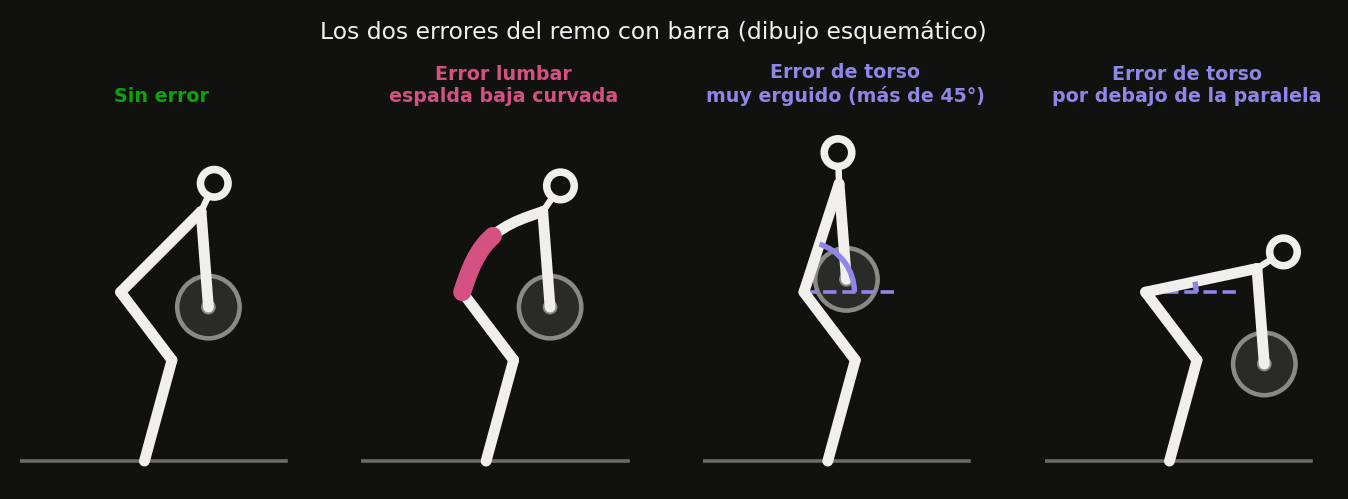

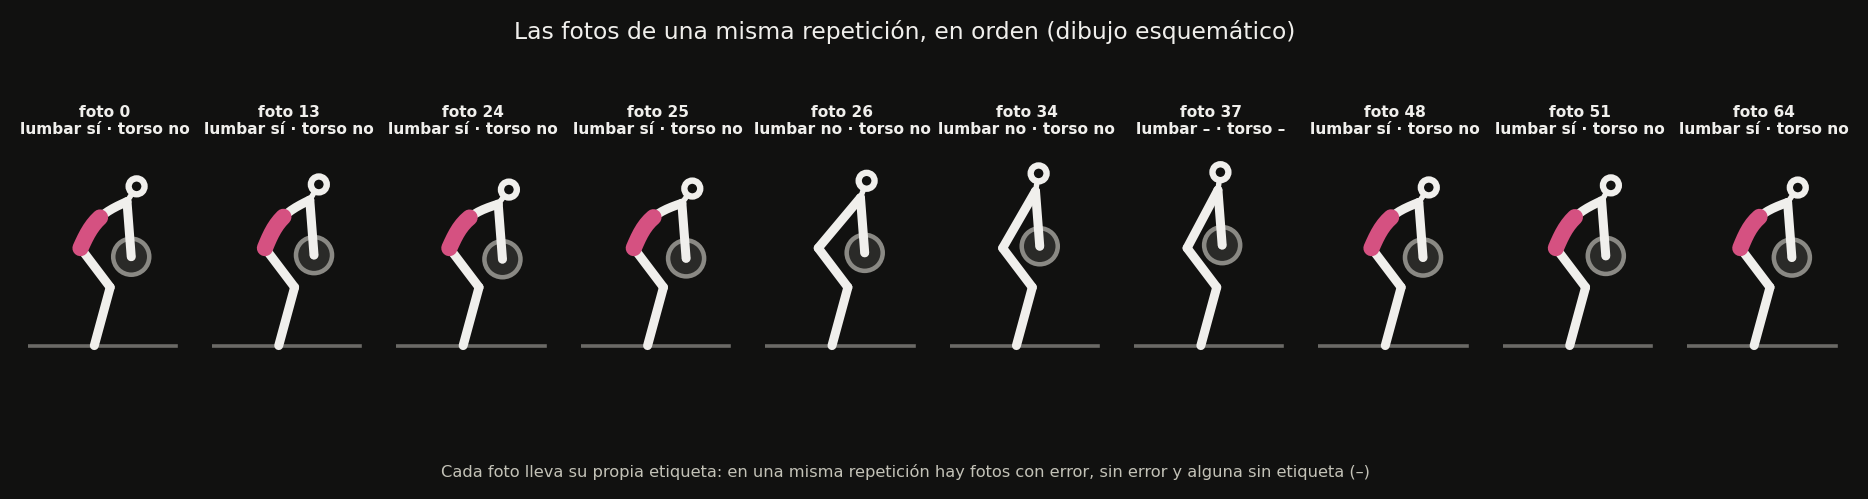

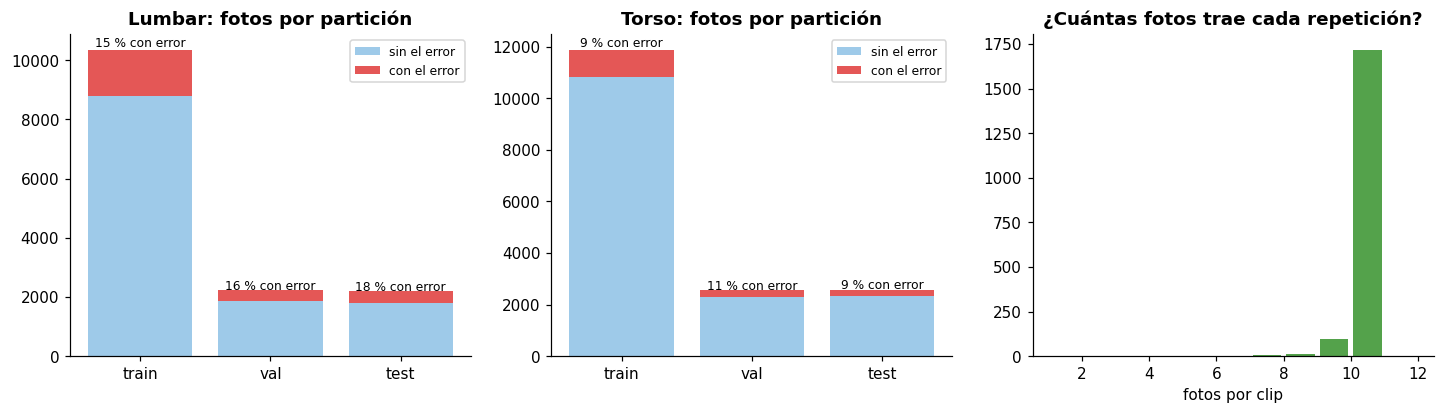

In [9]:
# ============================================================
# Figuras · muestras del dataset, un clip completo y el balance de clases
# ============================================================
with Seguro('Figura muestras'):
    rng = np.random.default_rng(1)
    grupos = [('Error lumbar', (Y[:, 0] == 1) & (S[:, 0] != '')), ('Error de torso', (Y[:, 1] == 1) & (S[:, 1] != '')),
              ('Sin error', (Y.sum(1) == 0) & (S != '').all(1))]
    fig, ax = plt.subplots(3, 5, figsize=(16, 9.5))
    for f, (t, m) in enumerate(grupos):
        cand = np.where(m & (SPLIT == 'train'))[0]
        sel = rng.choice(cand, min(5, len(cand)), replace=False) if len(cand) else []
        for c in range(5):
            a = ax[f, c]; a.axis('off')
            if c < len(sel):
                a.imshow(cv2.imread(str(FOTOS[IDS[sel[c]]]))[:, :, ::-1]); a.set_title(f'{t}\nclip {CLIP[sel[c]]}', fontsize=9)
    fig.suptitle('Fotos de entrenamiento de Fitness-AQA (remo con barra)', fontsize=13); guardar_fig(fig, 'fig00a_muestras')

with Seguro('Figura clip'):
    mixtos = [c for c in np.unique(CLIP[SPLIT == 'train']) if any(len(set(Y[(CLIP == c) & (S[:, j] != ''), j])) > 1 for j in range(2))]
    c0 = mixtos[0] if mixtos else CLIP[0]
    idx = sorted(np.where(CLIP == c0)[0], key=lambda i: int(IDS[i].split('_')[-1]) if IDS[i].split('_')[-1].isdigit() else 0)
    fig, ax = plt.subplots(1, len(idx), figsize=(2.3 * len(idx), 3.2), squeeze=False)
    for a, i in zip(ax[0], idx):
        a.imshow(cv2.imread(str(FOTOS[IDS[i]]))[:, :, ::-1]); a.axis('off')
        lab = lambda j: ('sí' if Y[i, j] else 'no') if S[i, j] else '–'
        a.set_title(f'{IDS[i].split("_")[-1]}\nlumbar {lab(0)} · torso {lab(1)}', fontsize=8)
    fig.suptitle(f'Las fotos de un mismo clip (repetición {c0}), en orden', fontsize=11); guardar_fig(fig, 'fig00b_clip')

with Seguro('Figura balance'):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    for j, e in enumerate(ERR):
        d = RESUMEN[RESUMEN.Error == NOMBRE_ERR[e]]
        ax[j].bar(d.Particion, d.Fotos - d.Con_error, color='#9ecae9', label='sin el error')
        ax[j].bar(d.Particion, d.Con_error, bottom=d.Fotos - d.Con_error, color='#E45756', label='con el error')
        for x_, (n_, p_) in enumerate(zip(d.Fotos, d.Porcentaje_con_error)):
            ax[j].text(x_, n_ * 1.01, f'{p_:.0f} % con error', ha='center', fontsize=8)
        ax[j].set_title(f'{NOMBRE_ERR[e]}: fotos por partición'); ax[j].legend(fontsize=8)
    ax[2].hist(pd.Series(CLIP).value_counts().values, bins=range(1, 13), color='#54A24B', rwidth=.85)
    ax[2].set_xlabel('fotos por clip'); ax[2].set_title('¿Cuántas fotos trae cada repetición?')
    guardar_fig(fig, 'fig00c_balance')

## Fase 0: Pose y recortes (preprocesamiento)

RTMPose da 17 puntos del cuerpo (se toma la persona más grande y centrada). Con ellos se arman 3 recortes cuadrados de 384 px y la fase 1 escoge uno: imagen completa (con relleno gris, no depende de la pose), persona (todos los puntos + 15 %) y tronco (hombros, caderas y rodillas + 25 %).

Todas las fotos, también las de los videos, pasan por las mismas transformaciones. La geométrica mueve los píxeles y la fotométrica cambia su valor.

| Transformación | Tipo |
|---|---|
| Reducir el lado mayor a 640 px | geométrica |
| Recorte cuadrado (con relleno gris si hace falta) | geométrica |
| Reescalar a la resolución de la red | geométrica |
| Normalizar con la media y la desviación de ImageNet | fotométrica |

In [10]:
# ============================================================
# 0b · Pose (las dos GPU a la vez) y recortes
# ============================================================
LADO_MAX, RES_GUARDA, UMB_KP = 640, (96 if PRUEBA else 384), 0.3
RECORTES = ['completa', 'persona', 'tronco']
ZPTS = {'persona': list(range(17)), 'tronco': [5, 6, 11, 12, 13, 14]}
MARG = {'persona': 1.15, 'tronco': 1.25}


class Pose:
    """RTMPose (rtmlib + onnxruntime). No hay plan B: si no carga, el notebook se detiene y nunca se mezclan dos estimadores."""
    def __init__(self, dev):
        self.tipo, self.proveedor, self.n = ('falsa', 'ninguno', 0) if PRUEBA else (None, None, 0)
        if PRUEBA:
            return
        import onnxruntime as ort
        if hasattr(ort, 'preload_dlls'):
            try: ort.preload_dlls()
            except Exception: pass
        from rtmlib import Body
        self.m = Body(mode='balanced', backend='onnxruntime', device=dev)          # «cuda:1» usa la segunda GPU (rtmlib 0.0.16)
        self.m(np.zeros((256, 256, 3), np.uint8)); self.tipo = 'rtmpose'
        self.proveedor = self.m.pose_model.session.get_providers()[0]

    def __call__(self, im):
        H, W = im.shape[:2]
        if self.tipo == 'falsa':
            self.n += 1; r = np.random.default_rng(self.n)
            base = np.array([[.5, .15]] * 5 + [[.42, .3], [.58, .3], [.4, .45], [.6, .45], [.4, .55], [.6, .55],
                             [.45, .55], [.55, .55], [.45, .72], [.55, .72], [.45, .9], [.55, .9]], np.float32)
            k = (base + r.normal(0, .005, base.shape)) * [W, H]
            k[[9, 10], 1] = H * (.6 + .15 * math.cos(2 * math.pi * self.n / 15))     # las muñecas suben y bajan: un jalón cada 15 fotogramas
            return [np.concatenate([k, np.full((17, 1), .9)], 1).astype(np.float32)]
        k, s = self.m(im)
        k = np.asarray(k, np.float32).reshape(-1, 17, 2); s = np.asarray(s, np.float32).reshape(-1, 17)
        return list(np.concatenate([k, np.clip(s, 0, 1)[..., None]], -1))


def principal(dets, H, W):
    """La persona más grande, centrada y nítida."""
    mejor, kp = -1, np.zeros((17, 3), np.float32)
    for k in dets:
        v = k[:, 2] > UMB_KP
        if v.sum() < 3:
            continue
        p = k[v, :2]; x0, y0 = p.min(0); x1, y1 = p.max(0)
        c = 1 - min(1, 1.5 * math.hypot((x0 + x1) / 2 / W - .5, (y0 + y1) / 2 / H - .5))
        sc = (x1 - x0) * (y1 - y0) / (H * W) * (.5 + .5 * c) * float(k[:, 2].mean())
        if sc > mejor:
            mejor, kp = sc, k
    return kp


def caja(kp, rec, H, W):
    if rec != 'completa':
        p = kp[ZPTS[rec]]; p = p[p[:, 2] > UMB_KP]
        if len(p) >= 2:
            x0, y0 = p[:, :2].min(0); x1, y1 = p[:, :2].max(0)
            return np.array([(x0 + x1) / 2, (y0 + y1) / 2, max(x1 - x0, y1 - y0, .12 * max(H, W)) * MARG[rec]], np.float32)
    return np.array([W / 2, H / 2, max(H, W)], np.float32)


def recortar(img, c, out):
    s = out / max(float(c[2]), 1.0)
    M = np.float32([[s, 0, out / 2 - s * c[0]], [0, s, out / 2 - s * c[1]]])
    return cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114))      # warpAffine no admite INTER_AREA


def reducir(im):
    """Lado mayor a 640 px (transformación geométrica). Igual para fotos del dataset y fotogramas de video."""
    s = LADO_MAX / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im


def leer_img(ruta):
    return reducir(cv2.imread(str(ruta), cv2.IMREAD_COLOR))


def recorte_jpg(im, c):
    """Recorte cuadrado a 384 px guardado en JPEG 92. Igual para fotos del dataset y fotogramas de video."""
    return cv2.imencode('.jpg', recortar(im, c, RES_GUARDA), [cv2.IMWRITE_JPEG_QUALITY, 92])[1].tobytes()


def procesar_lote(rutas, est, salida):
    for i, ruta in rutas:
        im = leer_img(ruta); H, W = im.shape[:2]
        kp = principal(est(im), H, W)
        cajas = {r: caja(kp, r, H, W) for r in RECORTES}
        salida[i] = dict(kp=kp, cajas=cajas, crops={r: recorte_jpg(im, cajas[r]) for r in RECORTES},
                         mini=cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (32, 32), interpolation=cv2.INTER_AREA))


with Etapa('pose y recortes'):
    # Uno por uno y antes de abrir los hilos: cargarlos a la vez podía mezclar dos estimadores.
    ESTIMADORES = [Pose(d) for d in DEVS]
    METODO_POSE = ESTIMADORES[0].tipo; PROVEEDOR_POSE = [e.proveedor for e in ESTIMADORES]
    assert len({e.tipo for e in ESTIMADORES}) == 1, 'las GPU quedaron con estimadores distintos'
    salidas = [dict() for _ in DEVS]
    hilos = [threading.Thread(target=procesar_lote, args=([(i, FOTOS[IDS[i]]) for i in range(g, N, len(DEVS))], e, salidas[g]))
             for g, e in enumerate(ESTIMADORES)]
    [h.start() for h in hilos]; [h.join() for h in hilos]
    REG = {}
    for s_ in salidas:
        REG.update(s_)
    assert len(REG) == N, f'la pose quedó incompleta: {len(REG)} de {N} fotos'
    KP = np.stack([REG[i]['kp'] for i in range(N)])
    CROPS = {r: [REG[i]['crops'][r] for i in range(N)] for r in RECORTES}
    CAJAS = {r: np.stack([REG[i]['cajas'][r] for i in range(N)]) for r in RECORTES}
    MINI = np.stack([REG[i]['mini'] for i in range(N)])
    del REG, salidas, ESTIMADORES
    # ángulo de la cámara: de perfil los hombros se ven casi uno encima del otro (ancho pequeño frente al tronco)
    ok4 = (KP[:, [5, 6, 11, 12], 2] > UMB_KP).all(1)
    LARGO = np.linalg.norm((KP[:, 5, :2] + KP[:, 6, :2]) / 2 - (KP[:, 11, :2] + KP[:, 12, :2]) / 2, axis=1)
    RAZON = np.where(ok4, np.abs(KP[:, 5, 0] - KP[:, 6, 0]) / np.maximum(LARGO, 1), np.nan)
    rz_tr = RAZON[(SPLIT == 'train') & np.isfinite(RAZON)]
    CORTES_V = np.quantile(rz_tr, [1 / 3, 2 / 3]) if len(rz_tr) else np.array([.3, .6])
    VISTA = np.where(np.isnan(RAZON), 'sin pose', np.where(RAZON < CORTES_V[0], 'de perfil',
                                                            np.where(RAZON < CORTES_V[1], 'intermedia', 'más de frente')))
    print(f'Pose con {METODO_POSE} en todas las fotos · proveedor {PROVEEDOR_POSE} · {100 * (KP[..., 2] > UMB_KP).mean():.0f} % de puntos visibles · '
          f'{100 * (KP[..., 2].max(1) == 0).mean():.1f} % de fotos sin persona')


def kp_en_recorte(i, rec, res):
    """Puntos de la foto i en las coordenadas del recorte `rec` de lado `res`."""
    c = CAJAS[rec][i]; s = res / max(float(c[2]), 1)
    k = KP[i].copy(); k[:, 0] = (k[:, 0] - c[0]) * s + res / 2; k[:, 1] = (k[:, 1] - c[1]) * s + res / 2
    return k

── pose y recortes · 0.01 h


load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend


load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-body7_pt-body7_420e-256x192-e48f03d0_20230504.onnx with onnxruntime backend


load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmpose-m_simcc-body7_pt-body7_420e-256x192-e48f03d0_20230504.onnx with onnxruntime backend
Pose con rtmpose en todas las fotos · proveedor ['CUDAExecutionProvider', 'CUDAExecutionProvider'] · 93 % de puntos visibles · 1.3 % de fotos sin persona
── pose y recortes: 27.2 min


En la figura, a la izquierda está la foto con el esqueleto que encontró RTMPose y a la derecha los 3 recortes que se comparan. Si el esqueleto cae sobre otra persona, los recortes «persona» y «tronco» salen mal.

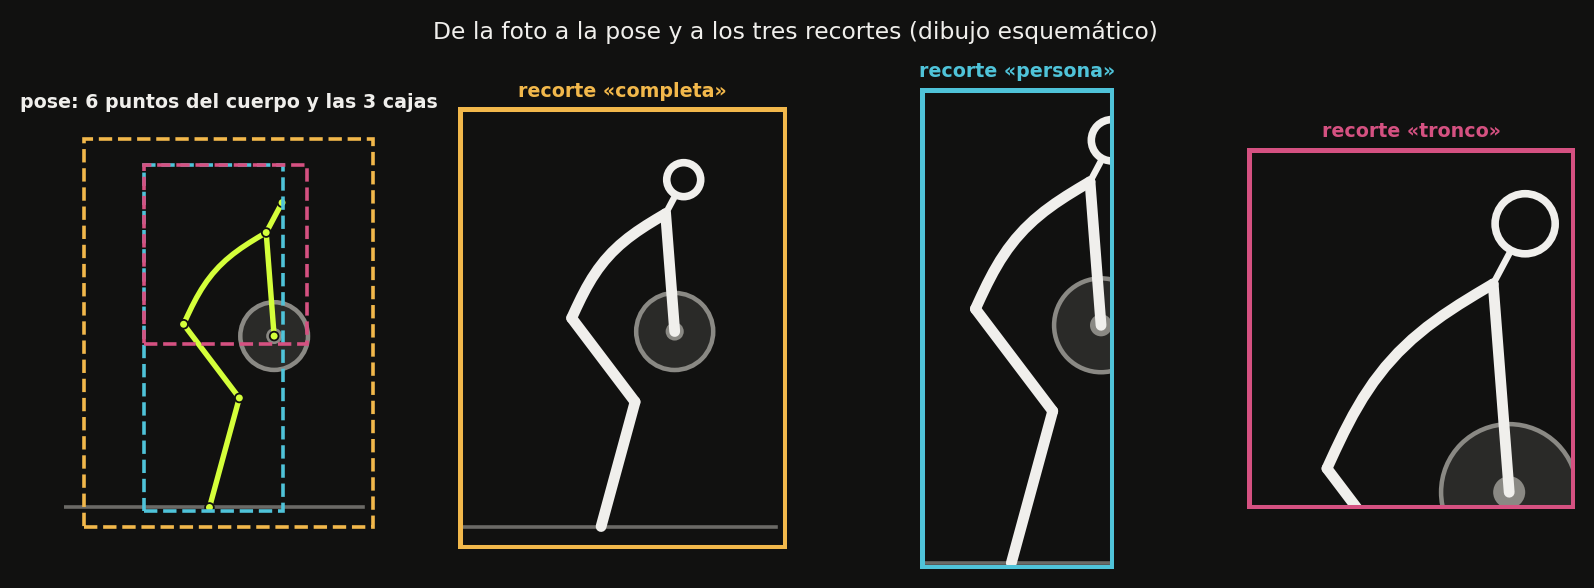

In [11]:
# ============================================================
# Figura · esqueleto y recortes
# ============================================================
with Seguro('Figura recortes'):
    rng = np.random.default_rng(0)
    ejemplos = []
    for j, t in ((0, 'error lumbar'), (1, 'error de torso')):
        c_ = np.where((Y[:, j] == 1) & (SPLIT == 'train'))[0]
        if len(c_): ejemplos.append((rng.choice(c_), t))
    c_ = np.where((Y.sum(1) == 0) & (S != '').all(1) & (SPLIT == 'train'))[0]
    if len(c_): ejemplos.append((rng.choice(c_), 'sin error'))
    fig, ax = plt.subplots(len(ejemplos), 4, figsize=(13, 3.4 * len(ejemplos)), squeeze=False)
    for f, (i, t) in enumerate(ejemplos):
        im = leer_img(FOTOS[IDS[i]]).copy(); k = KP[i]
        for a, b in ESQUELETO:
            if k[a, 2] > UMB_KP and k[b, 2] > UMB_KP:
                cv2.line(im, tuple(int(v) for v in k[a, :2]), tuple(int(v) for v in k[b, :2]), (0, 255, 0), 2)
        ax[f, 0].imshow(im[:, :, ::-1]); ax[f, 0].set_title(f'{t} · pose', fontsize=9)
        for c, r in enumerate(RECORTES):
            ax[f, c + 1].imshow(cv2.imdecode(np.frombuffer(CROPS[r][i], np.uint8), 1)[:, :, ::-1]); ax[f, c + 1].set_title(f'recorte «{r}»', fontsize=9)
        for a in ax[f]: a.axis('off')
    guardar_fig(fig, 'fig01_pose_recortes')

## Cómo se entrena (hiperparámetros y por qué)

| | Valor | Por qué |
|---|---|---|
| Cabeza | d → 256 → GELU → dropout 0,2 → 2 logits | son dos preguntas de sí o no y una foto puede tener los dos errores |
| Salida y pérdida | una sigmoide por error; BCE con peso de la clase con error = negativos / positivos (máx. 15) | softmax obligaría a escoger una sola opción; el error es minoría y el peso deja las probabilidades sin calibrar |
| Optimizador | AdamW (Loshchilov y Hutter, 2019), weight decay 0,05; lr de la red 3e-4 (ResNet-18), 2e-4 (ResNet-50) y 8e-5 (ConvNeXt-S); cabeza 1e-3 | la red aprende más lento que la cabeza para no borrar lo preentrenado, y más lento cuanto más grande es |
| Calendario | calentamiento de media época + coseno, hasta 10 épocas, parada por AP de validación (paciencia 3) | se guarda la mejor época |
| Lote | 64 | cabe en una T4 de 16 GB |
| Aumentos | volteo, zoom de 85 a 100 %, brillo y contraste, solo al entrenar | que no memorice; sin giros, porque cambian el ángulo del torso, que es lo que se mide |
| Predicción | promedio de la foto y su espejo | más estable |
| Métrica para escoger | AP media de los dos errores en validación | no depende del umbral y sirve con clases desbalanceadas |

Todas las redes usan el mismo recorte, resolución, épocas, validación y semillas, para que la diferencia salga de lo que se compara. En extracción la BatchNorm queda fija y en el ajuste completo se actualiza. La ResNet-18 sin preentrenar usa lr 1e-3 (no hay pesos que proteger) y 3e-4 (el de la preentrenada).

In [12]:
# ============================================================
# Entrenamiento: datos, modelo, una corrida y el planificador de las dos GPU
# ============================================================
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); DESV = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def decodificar(b, res):
    """JPEG del recorte → RGB a la resolución de la red (reescalado: transformación geométrica)."""
    im = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_COLOR)[:, :, ::-1]
    return cv2.resize(im, (res, res), interpolation=cv2.INTER_AREA) if im.shape[0] != res else np.ascontiguousarray(im)


class Modelo(nn.Module):
    """CNN de timm sin su clasificador (entrega un vector por imagen) + cabeza densa de 2 logits, uno por error.
    La normalización con la media y la desviación de ImageNet (transformación fotométrica) va dentro del modelo."""
    def __init__(self, nombre_timm, preentrenada=True, drop_path=0.0):
        super().__init__()
        kw = dict(pretrained=preentrenada and not PRUEBA, num_classes=0)
        if drop_path:
            kw['drop_path_rate'] = drop_path
        self.red = timm.create_model(nombre_timm, **kw)
        self.cab = nn.Sequential(nn.Linear(self.red.num_features, 256), nn.GELU(), nn.Dropout(.2), nn.Linear(256, 2))
        self.register_buffer('media', MEDIA.clone()); self.register_buffer('desv', DESV.clone())
    def prep(self, x): return (x.float() / 255 - self.media) / self.desv
    def forward(self, x): return self.cab(self.red(self.prep(x)))


def cargar(ruta, nombre_timm, drop_path, dev):
    """Modelo con sus pesos guardados, listo para predecir."""
    m = Modelo(nombre_timm, preentrenada=False, drop_path=drop_path)
    m.load_state_dict(torch.load(ruta, map_location='cpu'))
    return m.to(dev).eval()

def umbral_f1(y, p):
    """Corte con el mayor F1. Solo se llama con datos de validación."""
    o = np.argsort(-p); ys = y[o]; tp = np.cumsum(ys); fp = np.cumsum(1 - ys)
    k = int(np.argmax(2 * tp / np.maximum(tp + fp + ys.sum(), 1))); return float(p[o][k])


def met(y, p, t):
    pr = p >= t; tp = int((pr & (y == 1)).sum()); fp = int((pr & (y == 0)).sum()); fn = int((~pr & (y == 1)).sum()); tn = len(y) - tp - fp - fn
    return dict(F1=2 * tp / max(2 * tp + fp + fn, 1), Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1), Especificidad=tn / max(tn + fp, 1),
                AP=average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan, tp=tp, fp=fp, fn=fn, tn=tn)


def remuestras_clip(cl, B, semilla=0):
    """Bootstrap por clip: se sortean clips completos, porque las fotos de un mismo clip se parecen entre sí."""
    ug, inv = np.unique(cl, return_inverse=True); por = [np.where(inv == g)[0] for g in range(len(ug))]
    rng = np.random.default_rng(semilla)
    return [np.concatenate([por[g] for g in rng.integers(0, len(ug), len(ug))]) for _ in range(B)]


def ic(y, p, t, cl, B=None):
    """Intervalo del 95 % (percentiles 2,5 y 97,5) de cada métrica."""
    acum = defaultdict(list)
    for idx in remuestras_clip(cl, B or BOOT):
        r = met(y[idx], p[idx], t)
        for k in ('F1', 'Precision', 'Recall', 'Especificidad', 'AP'):
            if np.isfinite(r[k]):
                acum[k].append(r[k])
    return {k: (np.percentile(acum[k], [2.5, 97.5]) if acum[k] else np.array([np.nan, np.nan])) for k in ('F1', 'Precision', 'Recall', 'Especificidad', 'AP')}


def txt_ic(v):
    return f'{v[0]:.2f}–{v[1]:.2f}'


def ap_err(idx, P, split):
    """AP de cada error en las fotos `idx` que pertenecen a `split`."""
    r = {}
    for j, e in enumerate(ERR):
        m = S[idx, j] == split
        r[e] = average_precision_score(Y[idx][m, j], P[m, j]) if m.any() and 0 < Y[idx][m, j].sum() < m.sum() else np.nan
    return r


def por_clip(idx, P, j, split):
    """De foto a repetición: el clip tiene el error si alguna foto lo tiene, y su puntaje es la foto más probable."""
    m = S[idx, j] == split; c = CLIP[idx][m]; y = Y[idx][m, j]; p = P[m, j]
    u = np.unique(c); return np.array([y[c == k].max() for k in u]), np.array([p[c == k].max() for k in u])


def tabla_por_repeticion(umb):
    """Métricas por repetición en la prueba, con la regla y los umbrales congelados."""
    filas = []
    for j, e in enumerate(ERR):
        yt, pt = por_clip(ITE, P_TEST, j, 'test'); r = met(yt, pt, umb[e]); c_ = ic(yt, pt, umb[e], np.arange(len(yt)))
        filas.append(dict(Error=NOMBRE_ERR[e], Clips=len(yt), Con_error=int(yt.sum()), Recall=r['Recall'], Recall_IC=txt_ic(c_['Recall']),
                          Especificidad=r['Especificidad'], Especificidad_IC=txt_ic(c_['Especificidad']), F1=r['F1'], F1_IC=txt_ic(c_['F1']),
                          Precision=r['Precision'], Precision_IC=txt_ic(c_['Precision']), AP=r['AP'], AP_IC=txt_ic(c_['AP']), tp=r['tp'], fp=r['fp'], fn=r['fn'], tn=r['tn'], Umbral=umb[e]))
    return pd.DataFrame(filas)


LOCK_INIT = threading.Lock()
if not PRUEBA:                # bajar los pesos preentrenados una sola vez, antes de entrenar en paralelo
    for _r in list(REDES.values()) + (list(REDES_ALT.values()) if COMPROBAR_PESOS else []):
        timm.create_model(_r, pretrained=True, num_classes=0)


def aumentar(x, r):
    """Solo en entrenamiento. Geométricas: volteo y zoom. Fotométricas: contraste y brillo."""
    L = x.shape[0]
    if r.rand() < .5:
        x = x[:, ::-1]
    l = int(L * r.uniform(.85, 1)); ox, oy = r.randint(0, L - l + 1, 2)
    x = cv2.resize(np.ascontiguousarray(x[oy:oy + l, ox:ox + l]), (L, L))
    return np.clip(x.astype(np.float32) * r.uniform(.75, 1.25) + r.uniform(-20, 20), 0, 255).astype(np.uint8)


def ejemplo(i, rec, res, rng=None, voltear=False):
    """Una foto lista para la red: recorte reescalado, aumentos (si hay rng) y espejo."""
    x = decodificar(CROPS[rec][i], res)
    if rng is not None:
        x = aumentar(x, rng)
    if voltear:
        x = x[:, ::-1]
    return np.ascontiguousarray(x)


def lotes(idx, rec, res, lote, aug=False, voltear=False, semilla=0, adelante=4):
    """Lotes (fotos uint8 N×3×H×W, etiquetas, máscara) armados en paralelo con hilos: OpenCV libera el GIL, así que
    no hacen falta procesos hijos. La máscara solo deja las etiquetas de la partición de cada foto. Con `aug`, cada
    lote usa su propio generador aleatorio (semilla, número de lote): los aumentos son reproducibles."""
    from collections import deque
    bloques = [idx[a:a + lote] for a in range(0, len(idx), lote)]

    def armar(k, b):
        rng = np.random.RandomState((semilla * 100003 + k) % 2 ** 32) if aug else None
        x = np.stack([ejemplo(i, rec, res, rng, voltear) for i in b])
        m = (S[b] == SPLIT[b][:, None]).astype(np.float32)
        return torch.from_numpy(x).permute(0, 3, 1, 2), torch.from_numpy(np.where(m > 0, Y[b], 0).astype(np.float32)), torch.from_numpy(m)

    with ThreadPoolExecutor(3) as pool:
        cola = deque()
        for k, b in enumerate(bloques):
            cola.append(pool.submit(armar, k, b))
            if len(cola) > adelante:
                yield cola.popleft().result(timeout=900)
        while cola:
            yield cola.popleft().result(timeout=900)


def ultima_etapa(red, nombre):
    return nombre.startswith('layer4') if red.startswith('resnet') else (nombre.startswith('stages.3') or nombre.startswith('head'))


def preparar_estrategia(m, red, estr):
    for n, p in m.red.named_parameters():
        p.requires_grad = estr == 'completa' or (estr == 'parcial' and ultima_etapa(red, n))


def modo_entrenar(m, red, estr):
    m.train()
    if estr != 'completa':          # las capas fijas no actualizan su BatchNorm
        m.red.eval()
        if estr == 'parcial':
            for n, mod in m.red.named_modules():
                if n and ultima_etapa(red, n):
                    mod.train()


def perdida(z, y, m, pw):
    """BCE sobre logits, con peso para la clase con error."""
    l = F.binary_cross_entropy_with_logits(z, y, pos_weight=pw, reduction='none')
    return (l * m).sum() / m.sum().clamp(min=1)


@torch.no_grad()
def predecir(m, idx, rec, res, dev, lote=64):
    """Probabilidad de cada error: promedio de la foto y su espejo."""
    m.eval(); salida = []
    for vol in (False, True):
        P = []
        for x, _, _ in lotes(idx, rec, res, lote, voltear=vol):
            with torch.autocast('cuda', torch.float16, enabled=dev != 'cpu'):
                P.append(torch.sigmoid(m(x.to(dev).contiguous(memory_format=torch.channels_last)).float()).cpu().numpy())
        salida.append(np.concatenate(P))
    return np.mean(salida, 0)


@torch.no_grad()
def predecir_sin_espejo(m, idx, rec, res, dev, lote=64):
    """Solo para la curva de validación por época: más rápida."""
    m.eval(); P = []
    for x, _, _ in lotes(idx, rec, res, lote):
        with torch.autocast('cuda', torch.float16, enabled=dev != 'cpu'):
            P.append(torch.sigmoid(m(x.to(dev).contiguous(memory_format=torch.channels_last)).float()).cpu().numpy())
    return np.concatenate(P)


def ruta_pesos(c):
    """Los modelos finales quedan en la salida del notebook; los demás, en disco temporal hasta predecir la prueba."""
    return (OUT / 'modelos' if c.get('guardar') else WORK / 'pesos') / f"{c['nombre']}.pt"


def entrenar(cfg, dev):
    """Una corrida. cfg: red, estrategia, recorte, res, semilla, timm y opcionales ema, drop_path, epocas, desde_cero, lr_red, guardar.
    Aquí nunca se predice el conjunto de prueba."""
    t0 = time.time(); sem = cfg['semilla']
    red, estr, rec, res = cfg['red'], cfg['estrategia'], cfg['recorte'], cfg['res']
    itr, iva = np.where(SPLIT == 'train')[0], np.where(SPLIT == 'val')[0]
    with LOCK_INIT:          # las dos GPU comparten el generador de la CPU. torch.manual_seed reiniciaría también la otra GPU en plena corrida
        torch.default_generator.manual_seed(sem)
        m = Modelo(cfg['timm'], preentrenada=not cfg.get('desde_cero'), drop_path=cfg.get('drop_path', 0))
    m = m.to(dev).to(memory_format=torch.channels_last)
    if dev != 'cpu':
        with torch.cuda.device(dev):
            torch.cuda.manual_seed(sem)          # dropout y profundidad estocástica en esta GPU
    preparar_estrategia(m, red, estr)
    n_ent = sum(p.numel() for p in m.parameters() if p.requires_grad); n_tot = sum(p.numel() for p in m.parameters())
    lote = 8 if PRUEBA else 64
    n_lotes = max(1, len(itr) // lote)                 # se descarta el último lote incompleto
    Mtr = (S[itr] == 'train'); pos = (Y[itr] * Mtr).sum(0); neg = ((1 - Y[itr]) * Mtr).sum(0)
    pw = torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 15), dtype=torch.float32, device=dev)
    grupos = [{'params': m.cab.parameters(), 'lr': 1e-3}]
    pr = [p for p in m.red.parameters() if p.requires_grad]
    if pr:
        grupos.append({'params': pr, 'lr': cfg.get('lr_red', 1e-3 if cfg.get('desde_cero') else LR_RED[red])})
    opt = torch.optim.AdamW(grupos, weight_decay=.05)
    ep_max = cfg.get('epocas', EPOCAS_BASE); pasos = max(1, ep_max * n_lotes); cal = max(1, n_lotes // 2)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / cal) * .5 * (1 + math.cos(math.pi * min(s, pasos) / pasos)))
    scaler = torch.amp.GradScaler('cuda', enabled=dev != 'cpu')
    ema = timm.utils.ModelEmaV2(m, decay=.998) if cfg.get('ema') else None
    tb = None
    if not PRUEBA:
        try:
            from torch.utils.tensorboard import SummaryWriter
            tb = SummaryWriter(str(OUT / 'tensorboard' / cfg['nombre']))
        except Exception:
            tb = None
    yv = torch.tensor(np.where(S[iva] != '', Y[iva], 0), device=dev); mv_ = torch.tensor((S[iva] == 'val').astype(np.float32), device=dev)
    curva, mejor, estado, espera = [], -1, None, 0
    for ep in range(ep_max):
        te = time.time(); modo_entrenar(m, red, estr); suma, nb = 0., 0
        orden = np.random.default_rng(sem * 1000 + ep).permutation(itr)[:n_lotes * lote]
        for x, y, mk in lotes(orden, rec, res, lote, aug=True, semilla=sem * 1000 + ep):
            x = x.to(dev, non_blocking=True).contiguous(memory_format=torch.channels_last); y, mk = y.to(dev), mk.to(dev)
            with torch.autocast('cuda', torch.float16, enabled=dev != 'cpu'):
                z = m(x)
            loss = perdida(z.float(), y, mk, pw)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(m.parameters(), 1.); scaler.step(opt); scaler.update(); sched.step()
            if ema is not None:
                ema.update(m)
            suma += loss.item(); nb += 1
        mev = ema.module if ema is not None else m
        Pv = predecir_sin_espejo(mev, iva, rec, res, dev)
        with torch.no_grad():
            pv = perdida(torch.logit(torch.tensor(Pv, device=dev).clamp(1e-5, 1 - 1e-5)), yv, mv_, pw).item()
        a = ap_err(iva, Pv, 'val'); apm = float(np.nanmean(list(a.values())))
        curva.append(dict(epoca=ep + 1, perdida=suma / max(nb, 1), perdida_val=pv, ap_val=apm, segundos=time.time() - te))
        if tb is not None:
            tb.add_scalar('perdida/entrenamiento', suma / max(nb, 1), ep + 1); tb.add_scalar('perdida/validacion', pv, ep + 1)
            tb.add_scalar('AP/validacion', apm, ep + 1)
        if apm > mejor + 1e-4 or estado is None:
            mejor, espera = apm, 0; estado = {k: v.detach().cpu().clone() for k, v in mev.state_dict().items()}
        else:
            espera += 1
            if espera >= 3:
                break
        if horas() + 1.3 * (time.time() - te) / 3600 > CORTE:
            NOTAS.append(f'{cfg["nombre"]} se cortó por tiempo en la época {ep + 1}'); break
    if tb is not None:
        tb.close()
    m.load_state_dict(estado)
    torch.save(estado, ruta_pesos(cfg))
    P_va = predecir(m, iva, rec, res, dev)
    r = dict(cfg=cfg, curva=curva, ap_val=mejor, ap_val_err=ap_err(iva, P_va, 'val'), P_val=P_va, P_test=None,
             minutos=(time.time() - t0) / 60, gpu=dev, inicio_h=(t0 - T0) / 3600, n_train=len(itr),
             entrenables=n_ent, total=n_tot, mejor_epoca=int(np.argmax([c['ap_val'] for c in curva]) + 1))
    del m, opt, ema; torch.cuda.empty_cache()
    return r


RES = {}          # nombre de la corrida → resultado
IVA, ITE = np.where(SPLIT == 'val')[0], np.where(SPLIT == 'test')[0]


def estimado_min(c):
    f = {'congelada': .35, 'parcial': .55, 'completa': 1.0}[c['estrategia']]
    return c.get('epocas', EPOCAS_BASE) * 0.7 * ((SPLIT == 'train').sum() + 0.4 * len(IVA)) * f / VEL[c['red']] / 60 + 2


def correr(cfgs):
    """Reparte las corridas entre las GPU (un hilo por GPU). Salta lo que no alcance antes del corte."""
    cola = [c for c in cfgs if c['nombre'] not in RES]; lock = threading.Lock()

    def trabajador(dev):
        while True:
            with lock:
                if not cola:
                    return
                c = cola.pop(0)
            if horas() + 0.6 * estimado_min(c) / 60 > CORTE:
                NOTAS.append(f'Se saltó {c["nombre"]} (no alcanzaba antes del corte)'); print('se salta', c['nombre']); continue
            print(f'[{horas():.2f} h] ▶ {c["nombre"]} en {dev} (≈ {estimado_min(c):.0f} min)', flush=True)
            try:
                r = entrenar(c, dev)
                with lock:
                    RES[c['nombre']] = r
                print(f'[{horas():.2f} h] ■ {c["nombre"]}: AP val {r["ap_val"]:.3f} en {r["minutos"]:.1f} min', flush=True)
            except Exception as ex:
                import traceback; traceback.print_exc(); NOTAS.append(f'Falló {c["nombre"]}: {repr(ex)[:100]}')
                torch.cuda.empty_cache()
                if PRUEBA:
                    raise

    hs = [threading.Thread(target=trabajador, args=(d,)) for d in DEVS]
    [h.start() for h in hs]; [h.join() for h in hs]


def cfg(red, estr, rec, sem, **kw):
    extra = ''.join(f'_{k}{v}' for k, v in sorted(kw.items()) if k not in ('guardar', 'epocas'))
    return dict(red=red, estrategia=estr, recorte=rec, res=RES_RED, semilla=sem, nombre=f'{red}_{estr}_{rec}{extra}_s{sem}',
                timm=REDES_ALT[red] if kw.get('pesos') == 'alt' else REDES[red], **kw)


def hechas(cs):
    return [c for c in cs if c['nombre'] in RES]


def media_semillas(cs):
    """AP de validación media, desviación y número de corridas de un grupo."""
    v = [RES[c['nombre']]['ap_val'] for c in hechas(cs)]
    return (float(np.mean(v)), float(np.std(v, ddof=1) if len(v) > 1 else 0.0), len(v)) if v else (np.nan, np.nan, 0)


def pred(cs, cual='P_test'):
    """Promedio de las predicciones de las semillas de un grupo."""
    v = [RES[c['nombre']][cual] for c in hechas(cs) if RES[c['nombre']][cual] is not None]
    return np.mean(v, 0) if v and len(v) == len(hechas(cs)) else None      # si falta una semilla, no se reporta un promedio de menos con el mismo nombre

### Parámetros entrenables de cada red en cada estrategia

Se comprueba que cada estrategia entrena lo que dice (la «última etapa» pesa distinto en cada red).

,Red,Estrategia,Totales_M,Entrenables_M,Porcentaje
0,ResNet-18,congelada,11.308,0.132,1.166
1,ResNet-18,parcial,11.308,8.526,75.392
2,ResNet-18,completa,11.308,11.308,100.000
3,ResNet-50,congelada,24.033,0.525,2.185
4,ResNet-50,parcial,24.033,15.490,64.452
5,ResNet-50,completa,24.033,24.033,100.000
6,ConvNeXt-S,congelada,49.652,0.197,0.398
7,ConvNeXt-S,parcial,49.652,15.670,31.559
8,ConvNeXt-S,completa,49.652,49.652,100.000


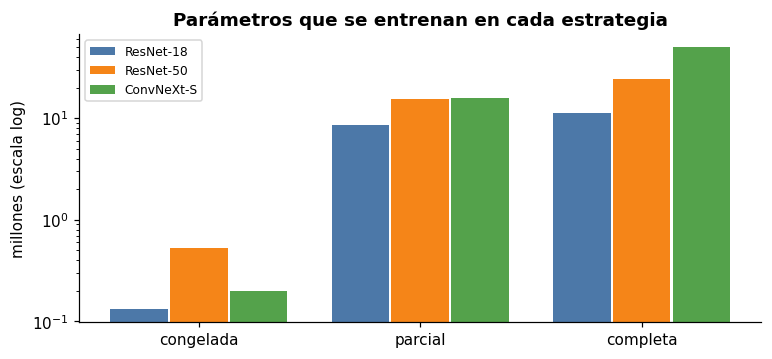

In [13]:
with Seguro('Parámetros entrenables'):
    filas = []
    for r in REDES:
        mm = Modelo(REDES[r], preentrenada=False); tot = sum(p.numel() for p in mm.parameters())
        for e in ESTRATEGIAS:
            preparar_estrategia(mm, r, e); ent = sum(p.numel() for p in mm.parameters() if p.requires_grad)
            filas.append(dict(Red=NOMBRE_RED[r], Estrategia=e, Totales_M=tot / 1e6, Entrenables_M=ent / 1e6, Porcentaje=100 * ent / tot))
        del mm
    T_PAR = pd.DataFrame(filas); guardar_tabla(T_PAR.round(3), 'parametros_entrenables')
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for a, r in enumerate(REDES):
        d = T_PAR[T_PAR.Red == NOMBRE_RED[r]]
        ax.bar(np.arange(3) + (a - 1) * .27, d.Entrenables_M, .26, color=COLR[r], label=NOMBRE_RED[r])
    ax.set_xticks(range(3)); ax.set_xticklabels(ESTRATEGIAS); ax.set_yscale('log'); ax.set_ylabel('millones (escala log)')
    ax.set_title('Parámetros que se entrenan en cada estrategia'); ax.legend(fontsize=8); guardar_fig(fig, 'fig02_parametros')

# Fase 1: ¿Qué recorte? (preparación de los datos)

Se probaron los 3 recortes con ResNet-50 de ajuste completo y 2 semillas cada uno. El de mayor AP media en validación se usó en todo lo que sigue.

── fase 1 · recorte · 0.46 h
[0.46 h] ▶ resnet50_completa_completa_s100 en cuda:0 (≈ 9 min)
[0.46 h] ▶ resnet50_completa_completa_s101 en cuda:1 (≈ 9 min)
[0.60 h] ■ resnet50_completa_completa_s100: AP val 0.698 en 8.0 min
[0.60 h] ▶ resnet50_completa_persona_s100 en cuda:0 (≈ 9 min)
[0.65 h] ■ resnet50_completa_completa_s101: AP val 0.694 en 11.3 min
[0.65 h] ▶ resnet50_completa_persona_s101 en cuda:1 (≈ 9 min)
[0.77 h] ■ resnet50_completa_persona_s100: AP val 0.689 en 10.4 min
[0.77 h] ▶ resnet50_completa_tronco_s100 en cuda:0 (≈ 9 min)
[0.83 h] ■ resnet50_completa_persona_s101: AP val 0.685 en 10.8 min
[0.83 h] ▶ resnet50_completa_tronco_s101 en cuda:1 (≈ 9 min)
[0.89 h] ■ resnet50_completa_tronco_s100: AP val 0.722 en 7.5 min
[0.98 h] ■ resnet50_completa_tronco_s101: AP val 0.730 en 9.2 min
── fase 1 · recorte: 31.3 min


,Recorte,AP_val,DE,corridas
0,completa,0.6959,0.0029,2
1,persona,0.6873,0.0027,2
2,tronco,0.7262,0.0056,2


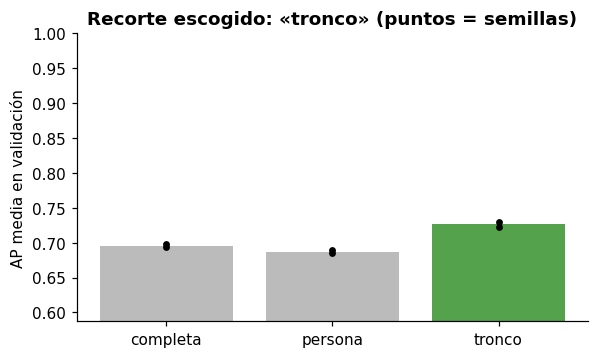

Recorte escogido: tronco


In [14]:
with Etapa('fase 1 · recorte'):
    # semillas 100+: así las corridas que escogieron el recorte no se reusan en la comparación de la fase 2
    F1C = {r: [cfg('resnet50', 'completa', r, s) for s in SEM_RECORTE] for r in RECORTES}
    correr([c for v in F1C.values() for c in v])
    T_REC = pd.DataFrame([dict(Recorte=r, AP_val=media_semillas(v)[0], DE=media_semillas(v)[1], corridas=media_semillas(v)[2])
                          for r, v in F1C.items()])
    assert T_REC.AP_val.notna().any(), 'Ninguna corrida de la fase 1 terminó'
    REC = T_REC.sort_values('AP_val', ascending=False).Recorte.iloc[0]
guardar_tabla(T_REC.round(4), 'fase1_recorte')
with Seguro('Figura recorte'):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for k, (r, v) in enumerate(F1C.items()):
        aps = [RES[c['nombre']]['ap_val'] for c in hechas(v)]
        ax.bar(k, np.mean(aps) if aps else np.nan, color='#54A24B' if r == REC else '#bbbbbb'); ax.scatter([k] * len(aps), aps, color='k', zorder=3, s=12)
    ax.set_xticks(range(3)); ax.set_xticklabels(RECORTES); ax.set_ylabel('AP media en validación')
    ax.set_title(f'Recorte escogido: «{REC}» (puntos = semillas)'); ax.set_ylim(max(0, np.nanmin(T_REC.AP_val) - .1), 1); guardar_fig(fig, 'fig03_recorte')
print('Recorte escogido:', REC)

Los recortes se probaron solo con ResNet-50 de ajuste completo por el límite de tiempo de GPU en Kaggle: probarlos con las 3 redes y las 3 estrategias habría multiplicado las corridas por 9. Por eso no se comprobó si otra red preferiría otro recorte.

# Fase 2: Comparación principal: 3 redes × 3 estrategias × 3 semillas

Se entrenaron las 3 redes con las 3 estrategias y 3 semillas, todas con el mismo recorte, resolución y máximo de épocas. Ganó la combinación con mayor AP media en validación. Además se entrenó la ResNet-18 con pesos aleatorios y dos tasas de aprendizaje, y la mejor se comparó con la ResNet-18 de ajuste completo, para medir cuánto aporta ImageNet.

In [15]:
with Etapa('fase 2 · redes y estrategias'):
    F2 = {(r, e): [cfg(r, e, REC, s) for s in SEMILLAS] for r in REDES for e in ESTRATEGIAS}
    F2_SP = {'lr 1e-3': [cfg('resnet18', 'completa', REC, s, desde_cero=1) for s in SEMILLAS],
             'lr 3e-4 (igual a la preentrenada)': [cfg('resnet18', 'completa', REC, s, desde_cero=1, lr_red=LR_RED['resnet18']) for s in SEMILLAS]}
    correr([c for s in SEMILLAS for v in F2.values() for c in v if c['semilla'] == s] + [c for v in F2_SP.values() for c in v])
    filas = []
    for (r, e), v in F2.items():
        h = hechas(v); ms = media_semillas(v)
        filas.append(dict(Red=NOMBRE_RED[r], Estrategia=e, AP_val=ms[0], DE=ms[1],
                          AP_val_lumbar=np.mean([RES[c['nombre']]['ap_val_err']['lumbar'] for c in h]) if h else np.nan,
                          AP_val_torso=np.mean([RES[c['nombre']]['ap_val_err']['torso'] for c in h]) if h else np.nan,
                          Mejor_epoca=np.mean([RES[c['nombre']]['mejor_epoca'] for c in h]) if h else np.nan,
                          Minutos=np.mean([RES[c['nombre']]['minutos'] for c in h]) if h else np.nan, corridas=ms[2], red=r, estrategia=e))
    T_GRID = pd.DataFrame(filas)
    g = T_GRID.dropna(subset=['AP_val']).sort_values('AP_val', ascending=False).iloc[0]
    GANA = (g.red, g.estrategia)
    T_SP = pd.DataFrame([dict(Configuracion=k, AP_val=media_semillas(v)[0], DE=media_semillas(v)[1], corridas=media_semillas(v)[2]) for k, v in F2_SP.items()])
    SP_MEJOR = T_SP.dropna(subset=['AP_val']).sort_values('AP_val', ascending=False).Configuracion.iloc[0]
    CTRL = media_semillas(F2_SP[SP_MEJOR])
guardar_tabla(T_GRID.drop(columns=['red', 'estrategia']).round(4), 'fase2_redes_estrategias')
guardar_tabla(T_SP.round(4), 'fase2_resnet18_sin_preentrenar')
print(f'Ganador en validación: {NOMBRE_RED[GANA[0]]} · {GANA[1]} · ResNet-18 sin preentrenar ({SP_MEJOR}): AP val {CTRL[0]:.3f} ± {CTRL[1]:.3f}')

── fase 2 · redes y estrategias · 0.98 h
[0.98 h] ▶ resnet18_congelada_tronco_s0 en cuda:0 (≈ 3 min)
[0.98 h] ▶ resnet18_parcial_tronco_s0 en cuda:1 (≈ 3 min)
[1.12 h] ■ resnet18_congelada_tronco_s0: AP val 0.568 en 8.1 min
[1.12 h] ▶ resnet18_completa_tronco_s0 en cuda:0 (≈ 4 min)
[1.14 h] ■ resnet18_parcial_tronco_s0: AP val 0.787 en 9.1 min
[1.14 h] ▶ resnet50_congelada_tronco_s0 en cuda:1 (≈ 4 min)
[1.24 h] ■ resnet50_congelada_tronco_s0: AP val 0.615 en 6.5 min
[1.24 h] ▶ resnet50_parcial_tronco_s0 en cuda:1 (≈ 6 min)
[1.29 h] ■ resnet18_completa_tronco_s0: AP val 0.854 en 10.5 min
[1.29 h] ▶ resnet50_completa_tronco_s0 en cuda:0 (≈ 9 min)
[1.41 h] ■ resnet50_completa_tronco_s0: AP val 0.727 en 6.9 min
[1.41 h] ▶ convnext_s_congelada_tronco_s0 en cuda:0 (≈ 9 min)
[1.41 h] ■ resnet50_parcial_tronco_s0: AP val 0.671 en 10.0 min
[1.41 h] ▶ convnext_s_parcial_tronco_s0 en cuda:1 (≈ 12 min)
[1.51 h] ■ convnext_s_congelada_tronco_s0: AP val 0.547 en 6.2 min
[1.51 h] ▶ convnext_s_complet

,Red,Estrategia,AP_val,DE,AP_val_lumbar,AP_val_torso,Mejor_epoca,Minutos,corridas
0,ResNet-18,congelada,0.5748,0.0070,0.6093,0.5663,6.6667,7.0301,3
1,ResNet-18,parcial,0.7819,0.0150,0.7677,0.8067,6.3333,7.5085,3
2,ResNet-18,completa,0.8548,0.0040,0.8709,0.8573,9.3333,9.6452,3
3,ResNet-50,congelada,0.6191,0.0039,0.6897,0.5626,3.6667,6.5713,3
4,ResNet-50,parcial,0.6761,0.0054,0.7499,0.6220,4.3333,7.5162,3
5,ResNet-50,completa,0.7234,0.0151,0.7376,0.7334,4.6667,8.0517,3
6,ConvNeXt-S,congelada,0.5557,0.0088,0.6171,0.5096,2.3333,5.9781,3
7,ConvNeXt-S,parcial,0.6492,0.0012,0.6809,0.6346,5.3333,8.4660,3
8,ConvNeXt-S,completa,0.8990,0.0057,0.9140,0.8937,5.0000,14.4119,3


,Configuracion,AP_val,DE,corridas
0,lr 1e-3,0.5229,0.0122,3
1,lr 3e-4 (igual a la preentrenada),0.5150,0.0091,3


Ganador en validación: ConvNeXt-S · completa · ResNet-18 sin preentrenar (lr 1e-3): AP val 0.523 ± 0.012


En la figura de la izquierda se ve la AP media de validación de cada red y estrategia (± la variación entre semillas). A la derecha se ve cada error por separado: la barra es la media, cada punto es una semilla, la línea roja es la ResNet-18 sin preentrenar y la gris es el azar. Si dos barras se diferencian menos de lo que se separan sus puntos, no hay un ganador claro.

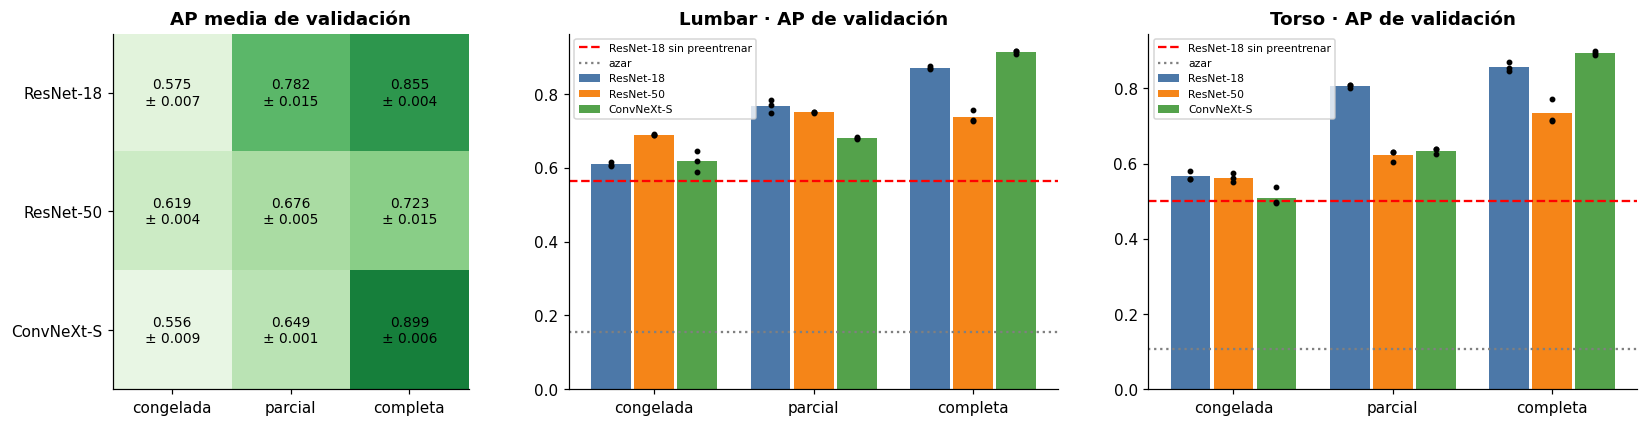

In [16]:
with Seguro('Figuras fase 2'):
    fig = plt.figure(figsize=(18, 4.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.3, 1.3])
    ax0 = fig.add_subplot(gs[0])
    M = T_GRID.pivot(index='red', columns='estrategia', values='AP_val').loc[list(REDES), ESTRATEGIAS]
    D = T_GRID.pivot(index='red', columns='estrategia', values='DE').loc[list(REDES), ESTRATEGIAS]
    im = ax0.imshow(M.values, cmap='Greens', vmin=np.nanmin(M.values) - .05, vmax=1)
    for a in range(3):
        for b in range(3):
            ax0.text(b, a, f'{M.values[a, b]:.3f}\n± {D.values[a, b]:.3f}', ha='center', va='center', fontsize=9)
    ax0.set_xticks(range(3)); ax0.set_xticklabels(ESTRATEGIAS); ax0.set_yticks(range(3)); ax0.set_yticklabels([NOMBRE_RED[r] for r in REDES])
    ax0.set_title('AP media de validación')
    for j, e in enumerate(ERR):
        ax = fig.add_subplot(gs[1 + j])
        for a, r in enumerate(REDES):
            for b, es in enumerate(ESTRATEGIAS):
                v = [RES[c['nombre']]['ap_val_err'][e] for c in hechas(F2[(r, es)])]
                x = b + (a - 1) * .27
                ax.bar(x, np.mean(v) if v else np.nan, .25, color=COLR[r], label=NOMBRE_RED[r] if b == 0 else None)
                ax.scatter([x] * len(v), v, color='k', s=8, zorder=3)
        vc = [RES[c['nombre']]['ap_val_err'][e] for c in hechas(F2_SP[SP_MEJOR])]
        if vc:
            ax.axhline(np.mean(vc), color='red', ls='--', label='ResNet-18 sin preentrenar')
        ax.axhline(Y[S[:, j] == 'val', j].mean(), color='gray', ls=':', label='azar')
        ax.set_xticks(range(3)); ax.set_xticklabels(ESTRATEGIAS); ax.set_title(f'{NOMBRE_ERR[e]} · AP de validación'); ax.legend(fontsize=7)
    guardar_fig(fig, 'fig04_redes_estrategias')

# Fase 3: Ajuste de hiperparámetros del ganador

Se comparó la configuración ganadora (base) contra una receta con tres cambios: promedio móvil de los pesos (EMA), profundidad estocástica (solo en ConvNeXt) y 14 épocas. Ambas se entrenaron con 3 semillas nuevas, porque la AP de la base en la fase 2 es optimista: era la mejor de 9 combinaciones. La receta se adoptaba solo si superaba a la base por más que la variación entre semillas; esa regla se fijó antes de correr. Como los tres cambios van juntos, no se sabe cuál aporta.

── fase 3 · hiperparámetros · 3.29 h
[3.29 h] ▶ convnext_s_completa_tronco_s50 en cuda:0 (≈ 21 min)
[3.29 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s50 en cuda:1 (≈ 29 min)
[3.58 h] ■ convnext_s_completa_tronco_s50: AP val 0.912 en 17.2 min
[3.58 h] ▶ convnext_s_completa_tronco_s51 en cuda:0 (≈ 21 min)
[3.75 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s50: AP val 0.918 en 27.9 min
[3.75 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s51 en cuda:1 (≈ 29 min)
[3.80 h] ■ convnext_s_completa_tronco_s51: AP val 0.901 en 13.7 min
[3.80 h] ▶ convnext_s_completa_tronco_s52 en cuda:0 (≈ 21 min)
[4.06 h] ■ convnext_s_completa_tronco_s52: AP val 0.900 en 15.3 min
[4.06 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s52 en cuda:0 (≈ 29 min)
[4.16 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s51: AP val 0.916 en 24.1 min
[4.47 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s52: AP val 0.905 en 24.6 min
── fase 3 · hiperparámetros: 70.8 min


,Cambio,AP_val,DE,corridas,Diferencia,Se_queda
0,base,0.9045,0.0067,3,0.0000,False
1,receta (EMA + profundidad estocástica + más ép...,0.9130,0.0068,3,0.0085,True


Umbral para aceptar un cambio: +0.0067 de AP · configuración final: {'ema': 1, 'epocas': 14, 'drop_path': 0.1}


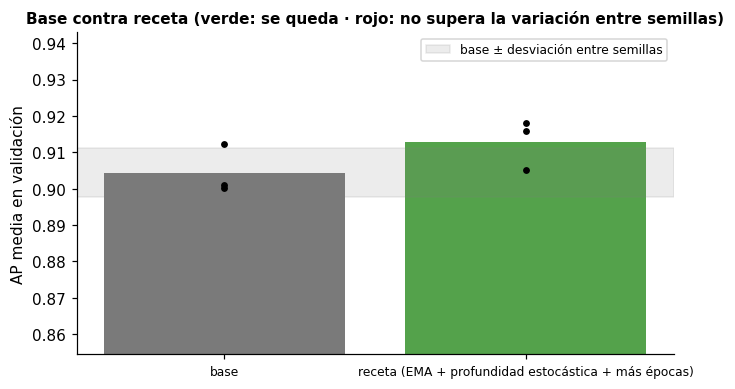

In [17]:
with Etapa('fase 3 · hiperparámetros'):
    rg, eg = GANA
    NOMBRE_RECETA = 'receta (EMA + profundidad estocástica + más épocas)' if rg == 'convnext_s' else 'receta (EMA + más épocas)'
    kw_receta = dict(ema=1, epocas=EPOCAS_RECETA, **({'drop_path': .1} if rg == 'convnext_s' else {}))
    VAR = {'base': [cfg(rg, eg, REC, s) for s in SEM_AJUSTE], NOMBRE_RECETA: [cfg(rg, eg, REC, s, **kw_receta) for s in SEM_AJUSTE]}
    correr([c for s in SEM_AJUSTE for v in VAR.values() for c in v if c['semilla'] == s])
    T_MEJ = pd.DataFrame([dict(Cambio=k, AP_val=media_semillas(v)[0], DE=media_semillas(v)[1], corridas=media_semillas(v)[2]) for k, v in VAR.items()])
    b_m, b_sd = T_MEJ.AP_val.iloc[0], T_MEJ.DE.iloc[0]
    sd_f2 = media_semillas(F2[(rg, eg)])[1]          # variación entre semillas medida con 3 semillas en la fase 2
    UMBRAL_MEJORA = max(.002, *(v for v in (b_sd, sd_f2) if np.isfinite(v)))
    T_MEJ['Diferencia'] = T_MEJ.AP_val - b_m
    T_MEJ['Se_queda'] = (T_MEJ.Diferencia > UMBRAL_MEJORA) & (T_MEJ.Cambio != 'base')
    RECETA_GANA = bool(T_MEJ.Se_queda.any())
    FINAL = dict(kw_receta) if RECETA_GANA else {}
guardar_tabla(T_MEJ.round(4), 'fase3_hiperparametros')
print(f'Umbral para aceptar un cambio: +{UMBRAL_MEJORA:.4f} de AP · configuración final: {FINAL or "la base"}')
with Seguro('Figura hiperparámetros'):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for k, (nm, v) in enumerate(VAR.items()):
        aps = [RES[c['nombre']]['ap_val'] for c in hechas(v)]
        col = '#7a7a7a' if nm == 'base' else ('#54A24B' if RECETA_GANA else '#E45756')
        ax.bar(k, np.mean(aps) if aps else np.nan, color=col); ax.scatter([k] * len(aps), aps, color='k', s=12, zorder=3)
    ax.axhspan(b_m - b_sd, b_m + b_sd, color='gray', alpha=.15, label='base ± desviación entre semillas')
    ax.set_xticks(range(len(VAR))); ax.set_xticklabels(list(VAR), fontsize=8); ax.set_ylabel('AP media en validación')
    ax.set_ylim(max(0, np.nanmin(T_MEJ.AP_val) - .05), min(1, np.nanmax(T_MEJ.AP_val) + .03))
    ax.set_title('Base contra receta (verde: se queda · rojo: no supera la variación entre semillas)', fontsize=10); ax.legend(fontsize=8)
    guardar_fig(fig, 'fig05_hiperparametros')

# Fase 4: Modelo final: ensamble de 5 semillas

Se entrenó la configuración escogida con 5 semillas nuevas y se promediaron sus probabilidades, lo que da un resultado más estable que una sola semilla. El número 5 se fijó de antemano y no se optimizó.

In [18]:
with Etapa('fase 4 · modelo final'):
    FIN = [cfg(rg, eg, REC, s, guardar=1, **FINAL) for s in SEM_FINAL]
    correr(FIN)
    FIN = hechas(FIN)
    assert FIN, 'No terminó ningún modelo final'
    res_f = FIN[0]['res']
    P_VAL = pred(FIN, 'P_val')
    ap_ens_val = float(np.nanmean(list(ap_err(IVA, P_VAL, 'val').values())))
    ap_base_val = float(np.nanmean(list(ap_err(IVA, pred(F2[(rg, eg)], 'P_val'), 'val').values())))
    T_CONF = pd.DataFrame([dict(Modelo=f'Base: {NOMBRE_RED[rg]} · {eg}', AP_val_media_semillas=media_semillas(F2[(rg, eg)])[0],
                                DE=media_semillas(F2[(rg, eg)])[1], AP_val_ensamble=ap_base_val, semillas=media_semillas(F2[(rg, eg)])[2]),
                           dict(Modelo=f'Final: {FINAL or "base"}', AP_val_media_semillas=media_semillas(FIN)[0], DE=media_semillas(FIN)[1],
                                AP_val_ensamble=ap_ens_val, semillas=len(FIN))])
guardar_tabla(T_CONF.round(4), 'fase4_base_vs_final')

── fase 4 · modelo final · 4.47 h
[4.47 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s11 en cuda:1 (≈ 29 min)
[4.47 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s10 en cuda:0 (≈ 29 min)
[4.80 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s10: AP val 0.907 en 20.1 min
[4.80 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s12 en cuda:0 (≈ 29 min)
[4.83 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s11: AP val 0.908 en 21.9 min
[4.83 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s13 en cuda:1 (≈ 29 min)
[5.17 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s12: AP val 0.913 en 21.7 min
[5.17 h] ▶ convnext_s_completa_tronco_drop_path0.1_ema1_s14 en cuda:0 (≈ 29 min)
[5.27 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s13: AP val 0.903 en 26.0 min
[5.46 h] ■ convnext_s_completa_tronco_drop_path0.1_ema1_s14: AP val 0.910 en 17.8 min
── fase 4 · modelo final: 59.6 min


,Modelo,AP_val_media_semillas,DE,AP_val_ensamble,semillas
0,Base: ConvNeXt-S · completa,0.8990,0.0057,0.9155,3
1,"Final: {'ema': 1, 'epocas': 14, 'drop_path': 0.1}",0.9083,0.0036,0.9211,5


# Fase 4b: ¿Cambia el resultado con otros pesos de partida?

Cada red parte de pesos preentrenados distintos, así que la fase 2 compara arquitectura y pesos a la vez. Para separarlos, se repitieron ResNet-50 y ConvNeXt-S con otros pesos de ImageNet-1k (`resnet50.tv_in1k` y `convnext_small.fb_in1k`). Esta fase no decide nada y solo usa validación.

In [19]:
T_PESOS = pd.DataFrame()
with Etapa('fase 4b · pesos de partida'):
    if COMPROBAR_PESOS:
        F2P = {(r, e): [cfg(r, e, REC, s, pesos='alt') for s in SEMILLAS] for r in REDES_ALT for e in (['completa'] if PRUEBA else ESTRATEGIAS)}
        correr([c for v in F2P.values() for c in v])
        filas = []
        for (r, e), v in F2P.items():
            a, b = media_semillas(F2[(r, e)]), media_semillas(v)
            filas.append(dict(Red=NOMBRE_RED[r], Estrategia=e, Pesos_original=REDES[r], AP_val_original=a[0], DE_original=a[1],
                              Pesos_alternos=REDES_ALT[r], AP_val_alternos=b[0], DE_alternos=b[1], Diferencia=b[0] - a[0], corridas=b[2]))
        T_PESOS = pd.DataFrame(filas); guardar_tabla(T_PESOS.round(4), 'fase4b_pesos_de_partida')
    else:
        print('Comprobación de pesos desactivada.')

── fase 4b · pesos de partida · 5.46 h
[5.46 h] ▶ resnet50_congelada_tronco_pesosalt_s0 en cuda:0 (≈ 4 min)
[5.46 h] ▶ resnet50_congelada_tronco_pesosalt_s1 en cuda:1 (≈ 4 min)
[5.62 h] ■ resnet50_congelada_tronco_pesosalt_s0: AP val 0.615 en 9.3 min
[5.62 h] ▶ resnet50_congelada_tronco_pesosalt_s2 en cuda:0 (≈ 4 min)
[5.62 h] ■ resnet50_congelada_tronco_pesosalt_s1: AP val 0.620 en 9.4 min
[5.62 h] ▶ resnet50_parcial_tronco_pesosalt_s0 en cuda:1 (≈ 6 min)
[5.76 h] ■ resnet50_parcial_tronco_pesosalt_s0: AP val 0.796 en 8.3 min
[5.76 h] ▶ resnet50_parcial_tronco_pesosalt_s1 en cuda:1 (≈ 6 min)
[5.77 h] ■ resnet50_congelada_tronco_pesosalt_s2: AP val 0.624 en 9.1 min
[5.77 h] ▶ resnet50_parcial_tronco_pesosalt_s2 en cuda:0 (≈ 6 min)
[5.85 h] ■ resnet50_parcial_tronco_pesosalt_s1: AP val 0.805 en 5.7 min
[5.85 h] ▶ resnet50_completa_tronco_pesosalt_s0 en cuda:1 (≈ 9 min)
[5.93 h] ■ resnet50_parcial_tronco_pesosalt_s2: AP val 0.789 en 9.4 min
[5.93 h] ▶ resnet50_completa_tronco_pesosalt_s1

,Red,Estrategia,Pesos_original,AP_val_original,DE_original,Pesos_alternos,AP_val_alternos,DE_alternos,Diferencia,corridas
0,ResNet-50,congelada,resnet50.a1_in1k,0.6191,0.0039,resnet50.tv_in1k,0.6199,0.0045,0.0007,3
1,ResNet-50,parcial,resnet50.a1_in1k,0.6761,0.0054,resnet50.tv_in1k,0.7968,0.0080,0.1206,3
2,ResNet-50,completa,resnet50.a1_in1k,0.7234,0.0151,resnet50.tv_in1k,0.8565,0.0118,0.1331,3
3,ConvNeXt-S,congelada,convnext_small.fb_in22k_ft_in1k,0.5557,0.0088,convnext_small.fb_in1k,0.6102,0.0107,0.0545,3
4,ConvNeXt-S,parcial,convnext_small.fb_in22k_ft_in1k,0.6492,0.0012,convnext_small.fb_in1k,0.6610,0.0040,0.0118,3
5,ConvNeXt-S,completa,convnext_small.fb_in22k_ft_in1k,0.8990,0.0057,convnext_small.fb_in1k,0.8764,0.0054,-0.0226,3


── fase 4b · pesos de partida: 89.0 min


### Curvas de pérdida y de validación

En la figura hay una curva por red y estrategia (primera semilla) y otra del modelo final. A la izquierda se ve la pérdida de entrenamiento (línea) y la de validación (guiones); a la derecha, la AP de validación. Si la pérdida de validación sube mientras la de entrenamiento baja, hay sobreajuste. Todas las curvas están en `curvas_todas.csv` y en TensorBoard.

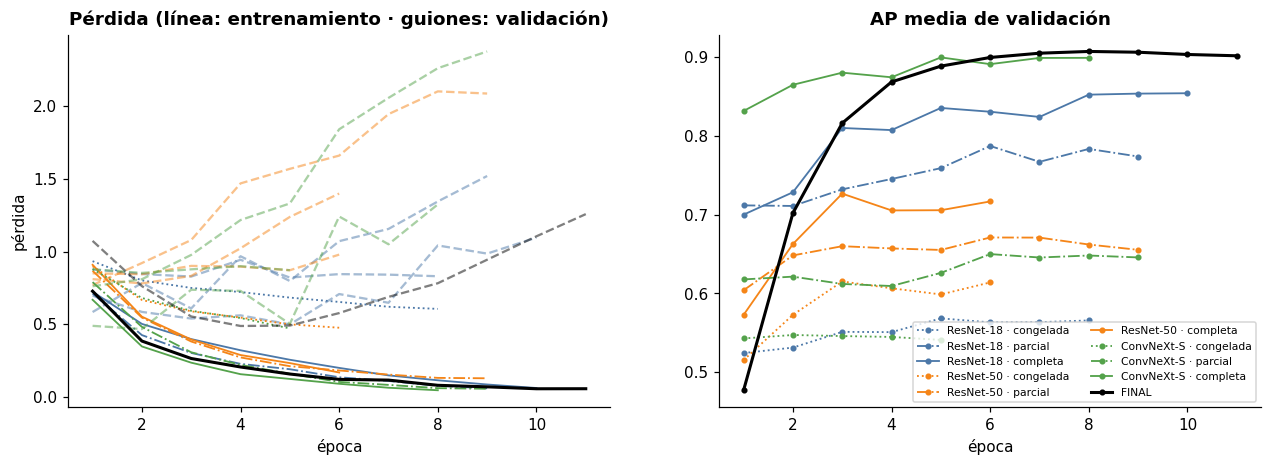

In [20]:
with Seguro('Figura curvas'):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    sel = [(NOMBRE_RED[r] + ' · ' + e, F2[(r, e)][0]['nombre'], COLR[r], {'congelada': ':', 'parcial': '-.', 'completa': '-'}[e])
           for r in REDES for e in ESTRATEGIAS] + [('FINAL', FIN[0]['nombre'], 'black', '-')]
    for et, n, col, ls in sel:
        if n not in RES:
            continue
        c = pd.DataFrame(RES[n]['curva'])
        ax[0].plot(c.epoca, c.perdida, color=col, ls=ls, lw=2 if et == 'FINAL' else 1.2, label=et)
        ax[0].plot(c.epoca, c.perdida_val, color=col, ls='--', alpha=.5)
        ax[1].plot(c.epoca, c.ap_val, color=col, ls=ls, marker='o', ms=3, lw=2 if et == 'FINAL' else 1.2, label=et)
    ax[0].set_title('Pérdida (línea: entrenamiento · guiones: validación)'); ax[0].set_xlabel('época'); ax[0].set_ylabel('pérdida')
    ax[1].set_title('AP media de validación'); ax[1].set_xlabel('época'); ax[1].legend(fontsize=7, ncol=2)
    guardar_fig(fig, 'fig06_curvas')
pd.DataFrame([dict(corrida=n, **c) for n, r in RES.items() for c in r['curva']]).to_csv(OUT / 'tablas' / 'curvas_todas.csv', index=False)

# Fase 5: Evaluación en el conjunto de prueba

## Primero se congelan las decisiones

Antes de ver la prueba se escogieron en validación los umbrales (uno por foto y otro por repetición) y se guardó todo lo decidido en `decisiones_congeladas.json`. Hasta aquí ninguna corrida predijo la prueba, y el código no lo permite sin ese archivo.

In [21]:
UMB = {e: umbral_f1(Y[IVA][S[IVA, j] == 'val', j], P_VAL[S[IVA, j] == 'val', j]) for j, e in enumerate(ERR)}
UMB_CLIP = {e: umbral_f1(*por_clip(IVA, P_VAL, j, 'val')) for j, e in enumerate(ERR)}
DECISION = dict(congeladas_en=time.time(), recorte=REC, red=rg, estrategia=eg, receta=FINAL, modelos=[c['nombre'] for c in FIN],
                umbrales_por_foto=UMB, umbrales_por_repeticion=UMB_CLIP, metodo_pose=METODO_POSE)
json.dump(limpio(DECISION), open(OUT / 'decisiones_congeladas.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
display(pd.DataFrame([dict(Error=NOMBRE_ERR[e], Umbral_por_foto=UMB[e], Umbral_por_repeticion=UMB_CLIP[e]) for e in ERR]).round(3))


def predecir_prueba(cs):
    """Único lugar donde se predice el conjunto de prueba. Exige que las decisiones ya estén guardadas."""
    assert (OUT / 'decisiones_congeladas.json').exists(), 'Primero hay que congelar las decisiones'
    lock = threading.Lock()

    def trabajador(dev, cola):
        while True:
            with lock:
                if not cola:
                    return
                c = cola.pop(0)
            try:
                m = cargar(ruta_pesos(c), c['timm'], c.get('drop_path', 0), dev)
                RES[c['nombre']]['P_test'] = predecir(m, ITE, c['recorte'], c['res'], dev)
                del m
            except Exception as ex:
                import traceback; traceback.print_exc(); print('Falló la predicción de', c['nombre'], flush=True)
            torch.cuda.empty_cache()

    for _ in range(2):          # un segundo intento para lo que haya fallado
        cola = [c for c in hechas(cs) if RES[c['nombre']]['P_test'] is None]
        hs = [threading.Thread(target=trabajador, args=(d, cola)) for d in DEVS]
        [h.start() for h in hs]; [h.join() for h in hs]
    NOTAS.extend(f"Sin predicción de prueba: {c['nombre']}" for c in hechas(cs) if RES[c['nombre']]['P_test'] is None)


with Etapa('fase 5 · predecir la prueba'):
    TEST_PRIMER_USO = time.time()
    predecir_prueba(FIN + [c for v in F2.values() for c in v] + [c for v in F2_SP.values() for c in v])
    assert all(RES[c['nombre']]['P_test'] is not None for c in FIN), 'Falta la predicción de algún modelo final'
    P_TEST = pred(FIN)
print('Decisiones guardadas antes de tocar la prueba:', DECISION['congeladas_en'] < TEST_PRIMER_USO)

,Error,Umbral_por_foto,Umbral_por_repeticion
0,Lumbar,0.332,0.648
1,Torso,0.625,0.400


── fase 5 · predecir la prueba · 6.95 h
── fase 5 · predecir la prueba: 6.1 min
Decisiones guardadas antes de tocar la prueba: True


## Métricas

Como el error es minoría, un modelo que siempre dice «bien» tiene exactitud alta sin detectar nada. Por eso:
- AP: qué tan arriba quedan las fotos con error al ordenar por probabilidad, sin umbral. El azar es la proporción de errores.
- Precisión (de lo marcado, cuánto era error), recall (de los errores reales, cuántos encontró) y F1, con el umbral de validación.
- Especificidad (de lo correcto, cuánto dejó sin marcar). Con el recall se compara con los videos, porque no depende de la proporción de errores.
- IC 95 % por bootstrap por clip: se sortean clips completos 1 000 veces. Sortear fotos daría intervalos muy estrechos, porque las de un clip se parecen.
- Referencias: el clasificador trivial y, solo como contexto, el F1 del artículo.

In [22]:
def evaluar(Pv, Pt, nombre):
    filas = []
    for j, e in enumerate(ERR):
        mv, mt = S[IVA, j] == 'val', S[ITE, j] == 'test'
        yv, pv, yt, pt = Y[IVA][mv, j], Pv[mv, j], Y[ITE][mt, j], Pt[mt, j]
        t = umbral_f1(yv, pv); r = met(yt, pt, t); c_ = ic(yt, pt, t, CLIP[ITE][mt])
        filas.append(dict(Modelo=nombre, Error=NOMBRE_ERR[e], AP=r['AP'], AP_IC=txt_ic(c_['AP']), F1=r['F1'], F1_IC=txt_ic(c_['F1']),
                          Precision=r['Precision'], Precision_IC=txt_ic(c_['Precision']), Recall=r['Recall'], Recall_IC=txt_ic(c_['Recall']),
                          Especificidad=r['Especificidad'], Especificidad_IC=txt_ic(c_['Especificidad']), Umbral_val=t, tp=r['tp'], fp=r['fp'], fn=r['fn'], tn=r['tn'],
                          F1_trivial=2 * yt.mean() / (1 + yt.mean()), AP_azar=yt.mean(), F1_articulo_ref=PAPER[e]))
    return filas


with Etapa('fase 5 · evaluación'):
    NOMBRE_FINAL = f'FINAL ({NOMBRE_RED[rg]} · {eg} · ensamble de {len(FIN)})'
    filas = evaluar(P_VAL, P_TEST, NOMBRE_FINAL)
    for (r, e), v in F2.items():
        if pred(v) is not None:
            filas += evaluar(pred(v, 'P_val'), pred(v), f'{NOMBRE_RED[r]} · {e}')
    if pred(F2_SP[SP_MEJOR]) is not None:
        filas += evaluar(pred(F2_SP[SP_MEJOR], 'P_val'), pred(F2_SP[SP_MEJOR]), 'ResNet-18 sin preentrenar')
    TABLA = pd.DataFrame(filas)
guardar_tabla(TABLA[TABLA.Modelo == NOMBRE_FINAL].round(3), 'test_final')
guardar_tabla(TABLA.round(3), 'test_todos')

── fase 5 · evaluación · 7.05 h
── fase 5 · evaluación: 0.5 min


,Modelo,Error,AP,AP_IC,F1,F1_IC,Precision,Precision_IC,Recall,Recall_IC,Especificidad,Especificidad_IC,Umbral_val,tp,fp,fn,tn,F1_trivial,AP_azar,F1_articulo_ref
0,FINAL (ConvNeXt-S · completa · ensamble de 5),Lumbar,0.931,0.89–0.96,0.865,0.82–0.91,0.849,0.78–0.91,0.882,0.83–0.93,0.966,0.95–0.98,0.332,344,61,46,1740,0.302,0.178,0.634
1,FINAL (ConvNeXt-S · completa · ensamble de 5),Torso,0.817,0.72–0.89,0.767,0.69–0.82,0.772,0.68–0.85,0.762,0.68–0.83,0.977,0.97–0.98,0.625,179,53,56,2297,0.167,0.091,0.526


,Modelo,Error,AP,AP_IC,F1,F1_IC,Precision,Precision_IC,Recall,Recall_IC,Especificidad,Especificidad_IC,Umbral_val,tp,fp,fn,tn,F1_trivial,AP_azar,F1_articulo_ref
0,FINAL (ConvNeXt-S · completa · ensamble de 5),Lumbar,0.931,0.89–0.96,0.865,0.82–0.91,0.849,0.78–0.91,0.882,0.83–0.93,0.966,0.95–0.98,0.332,344,61,46,1740,0.302,0.178,0.634
1,FINAL (ConvNeXt-S · completa · ensamble de 5),Torso,0.817,0.72–0.89,0.767,0.69–0.82,0.772,0.68–0.85,0.762,0.68–0.83,0.977,0.97–0.98,0.625,179,53,56,2297,0.167,0.091,0.526
2,ResNet-18 · congelada,Lumbar,0.617,0.51–0.72,0.594,0.52–0.67,0.591,0.49–0.69,0.597,0.52–0.69,0.911,0.89–0.93,0.574,233,161,157,1640,0.302,0.178,0.634
3,ResNet-18 · congelada,Torso,0.480,0.36–0.59,0.482,0.39–0.56,0.415,0.31–0.50,0.574,0.47–0.68,0.919,0.90–0.94,0.768,135,190,100,2160,0.167,0.091,0.526
4,ResNet-18 · parcial,Lumbar,0.778,0.69–0.85,0.705,0.63–0.77,0.688,0.59–0.77,0.723,0.64–0.80,0.929,0.90–0.95,0.357,282,128,108,1673,0.302,0.178,0.634
5,ResNet-18 · parcial,Torso,0.736,0.62–0.82,0.676,0.58–0.74,0.712,0.59–0.80,0.643,0.55–0.73,0.974,0.96–0.98,0.608,151,61,84,2289,0.167,0.091,0.526
6,ResNet-18 · completa,Lumbar,0.865,0.80–0.91,0.786,0.72–0.84,0.806,0.72–0.87,0.767,0.69–0.83,0.960,0.94–0.97,0.480,299,72,91,1729,0.302,0.178,0.634
7,ResNet-18 · completa,Torso,0.820,0.73–0.88,0.745,0.67–0.81,0.726,0.63–0.81,0.766,0.68–0.83,0.971,0.96–0.98,0.379,180,68,55,2282,0.167,0.091,0.526
8,ResNet-50 · congelada,Lumbar,0.678,0.58–0.77,0.602,0.52–0.68,0.682,0.58–0.78,0.538,0.45–0.63,0.946,0.93–0.96,0.714,210,98,180,1703,0.302,0.178,0.634
9,ResNet-50 · congelada,Torso,0.442,0.32–0.56,0.489,0.39–0.57,0.405,0.30–0.49,0.617,0.50–0.73,0.909,0.89–0.93,0.675,145,213,90,2137,0.167,0.091,0.526


A la izquierda se ve la curva precisión-recall en la prueba: el punto rojo es el umbral escogido en validación y la línea gris es el azar. A la derecha, la matriz de confusión con ese umbral.

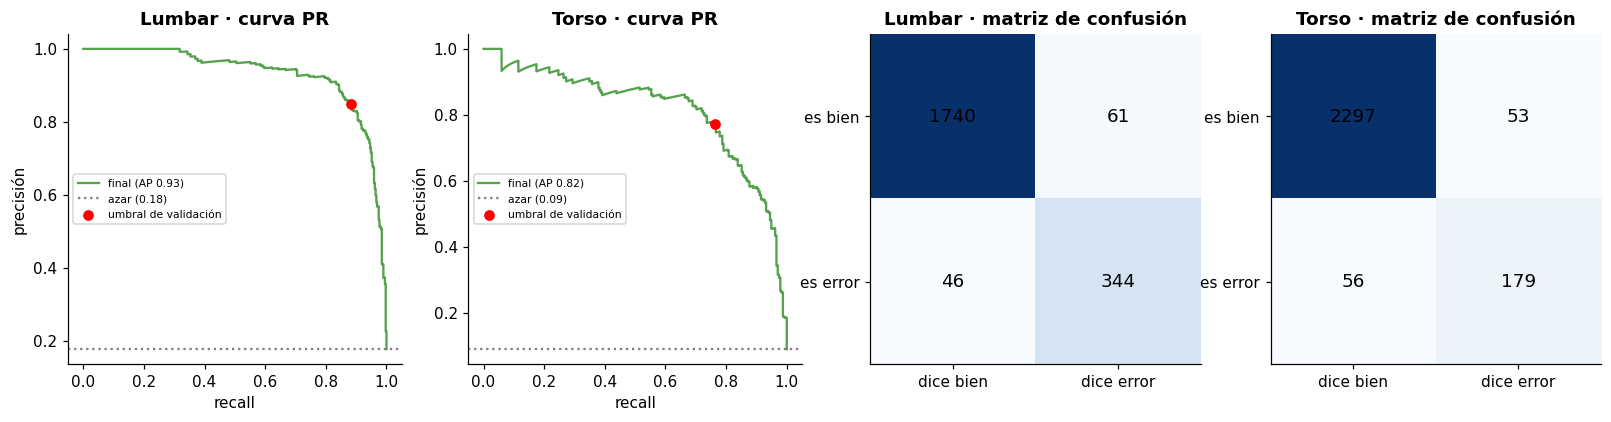

In [23]:
with Seguro('Figura PR y matrices'):
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.9))
    for j, e in enumerate(ERR):
        mt = S[ITE, j] == 'test'; yt, pt = Y[ITE][mt, j], P_TEST[mt, j]
        pr_, rc_, _ = precision_recall_curve(yt, pt)
        ax[j].plot(rc_, pr_, color='#54A24B', label=f'final (AP {average_precision_score(yt, pt):.2f})')
        ax[j].axhline(yt.mean(), color='gray', ls=':', label=f'azar ({yt.mean():.2f})')
        r = met(yt, pt, UMB[e]); ax[j].scatter([r['Recall']], [r['Precision']], color='red', zorder=3, label='umbral de validación')
        ax[j].set_xlabel('recall'); ax[j].set_ylabel('precisión'); ax[j].set_title(f'{NOMBRE_ERR[e]} · curva PR'); ax[j].legend(fontsize=7)
        cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
        ax[2 + j].imshow(cm, cmap='Blues')
        for a in range(2):
            for b in range(2):
                ax[2 + j].text(b, a, cm[a, b], ha='center', va='center', fontsize=12)
        ax[2 + j].set_xticks([0, 1]); ax[2 + j].set_xticklabels(['dice bien', 'dice error']); ax[2 + j].set_yticks([0, 1])
        ax[2 + j].set_yticklabels(['es bien', 'es error']); ax[2 + j].set_title(f'{NOMBRE_ERR[e]} · matriz de confusión')
    guardar_fig(fig, 'fig07_pr_confusion')

### ¿Las diferencias son reales?

Se calcula la diferencia de AP en la prueba entre pares de modelos con bootstrap pareado por clip. Si el IC 95 % no cruza el cero, es consistente. No decide nada: la elección ya se hizo en validación.

,A,B,Error,Diferencia_AP,IC_bajo,IC_alto,Conclusion
0,Final · 3 semillas,Base ConvNeXt-S · completa · 3 semillas,Lumbar,0.001,-0.010,0.011,sin diferencia consistente
1,Final · 3 semillas,Base ConvNeXt-S · completa · 3 semillas,Torso,-0.012,-0.047,0.012,sin diferencia consistente
2,Final · 5 semillas,Final · 3 semillas,Lumbar,-0.002,-0.004,0.001,sin diferencia consistente
3,Final · 5 semillas,Final · 3 semillas,Torso,-0.005,-0.018,0.005,sin diferencia consistente
4,ConvNeXt-S · completa,ConvNeXt-S · congelada,Lumbar,0.299,0.221,0.386,A es mejor
5,ConvNeXt-S · completa,ConvNeXt-S · congelada,Torso,0.414,0.319,0.494,A es mejor
6,ConvNeXt-S · completa,ConvNeXt-S · parcial,Lumbar,0.208,0.146,0.277,A es mejor
7,ConvNeXt-S · completa,ConvNeXt-S · parcial,Torso,0.265,0.178,0.359,A es mejor
8,ConvNeXt-S · completa,ResNet-18 · completa,Lumbar,0.067,0.037,0.105,A es mejor
9,ConvNeXt-S · completa,ResNet-18 · completa,Torso,0.014,-0.023,0.056,sin diferencia consistente


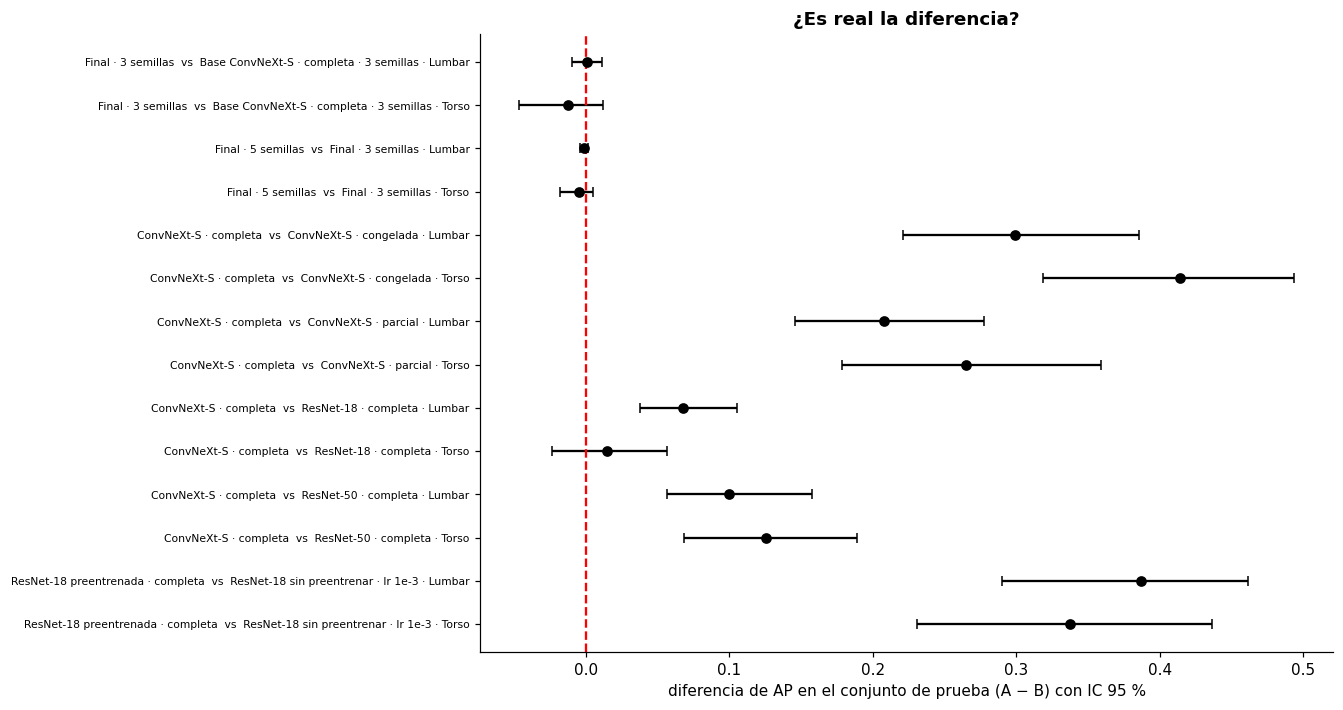

In [24]:
def dif_ap(Pa, Pb):
    out = []
    for j, e in enumerate(ERR):
        m = S[ITE, j] == 'test'; y, a, b, cl = Y[ITE][m, j], Pa[m, j], Pb[m, j], CLIP[ITE][m]
        d = [average_precision_score(y[i], a[i]) - average_precision_score(y[i], b[i])
             for i in remuestras_clip(cl, BOOT, 1) if 0 < y[i].sum() < len(i)]
        lo, hi = np.percentile(d, [2.5, 97.5]) if d else (np.nan, np.nan)
        out.append(dict(Error=NOMBRE_ERR[e], Diferencia_AP=average_precision_score(y, a) - average_precision_score(y, b), IC_bajo=lo, IC_alto=hi,
                        Conclusion='A es mejor' if lo > 0 else ('B es mejor' if hi < 0 else 'sin diferencia consistente')))
    return out


with Seguro('Comparaciones pareadas'):
    COMP = [('Final · 3 semillas', pred(FIN[:3]), f'Base {NOMBRE_RED[rg]} · {eg} · 3 semillas', pred(F2[(rg, eg)])),
            (f'Final · {len(FIN)} semillas', P_TEST, 'Final · 3 semillas', pred(FIN[:3]))]
    for e2 in ESTRATEGIAS:
        if e2 != eg:
            COMP.append((f'{NOMBRE_RED[rg]} · {eg}', pred(F2[(rg, eg)]), f'{NOMBRE_RED[rg]} · {e2}', pred(F2[(rg, e2)])))
    for r in REDES:
        if r != rg:
            er = T_GRID[T_GRID.red == r].sort_values('AP_val', ascending=False).estrategia.iloc[0]
            COMP.append((f'{NOMBRE_RED[rg]} · {eg}', pred(F2[(rg, eg)]), f'{NOMBRE_RED[r]} · {er}', pred(F2[(r, er)])))
    COMP.append(('ResNet-18 preentrenada · completa', pred(F2[('resnet18', 'completa')]), f'ResNet-18 sin preentrenar · {SP_MEJOR}', pred(F2_SP[SP_MEJOR])))
    filas = []
    for a, Pa, b, Pb in COMP:
        if Pa is not None and Pb is not None:
            filas += [dict(A=a, B=b, **d) for d in dif_ap(Pa, Pb)]
    T_DIF = pd.DataFrame(filas); guardar_tabla(T_DIF.round(3), 'comparaciones_pareadas')
    fig, ax = plt.subplots(figsize=(10, .45 * len(T_DIF) + 1))
    yy = np.arange(len(T_DIF))
    ax.errorbar(T_DIF.Diferencia_AP, yy, xerr=[(T_DIF.Diferencia_AP - T_DIF.IC_bajo).clip(lower=0), (T_DIF.IC_alto - T_DIF.Diferencia_AP).clip(lower=0)], fmt='o', color='k', capsize=3)
    ax.axvline(0, color='red', ls='--'); ax.set_yticks(yy); ax.set_yticklabels([f'{r.A}  vs  {r.B} · {r.Error}' for r in T_DIF.itertuples()], fontsize=7)
    ax.invert_yaxis(); ax.set_xlabel('diferencia de AP en el conjunto de prueba (A − B) con IC 95 %'); ax.set_title('¿Es real la diferencia?')
    guardar_fig(fig, 'fig08_comparaciones')

### De la foto a la repetición

Un clip es una repetición (5 a 10 fotos). Una repetición se marca con error si su foto más probable supera el umbral por repetición. El notebook 2 usa esta misma regla con los videos propios.

In [25]:
with Seguro('Por repetición'):          # si fallara, la corrida sigue y el notebook 2 recalcula esta tabla con las predicciones guardadas
    T_REP = tabla_por_repeticion(UMB_CLIP)
    guardar_tabla(T_REP.round(3), 'test_por_repeticion')

,Error,Clips,Con_error,Recall,Recall_IC,Especificidad,Especificidad_IC,F1,F1_IC,Precision,Precision_IC,AP,AP_IC,tp,fp,fn,tn,Umbral
0,Lumbar,276,84,0.845,0.77–0.92,0.943,0.91–0.97,0.855,0.79–0.91,0.866,0.79–0.93,0.906,0.86–0.95,71,11,13,181,0.648
1,Torso,276,70,0.814,0.71–0.90,0.869,0.82–0.91,0.740,0.65–0.81,0.679,0.58–0.77,0.864,0.79–0.92,57,27,13,179,0.400


# Fase 6: ¿En qué se fija el modelo?

Grad-CAM (Selvaraju y otros, 2017) dibuja sobre la foto qué zonas influyen en el logit del error (rojo = más), promediando las semillas. Además se mide el % del mapa por zona del cuerpo frente al % de su área (si la espalda baja recibe varias veces su área, el modelo se fija en ella más de lo que le toca) y dentro de la silueta de la pose. Las zonas son franjas 2D aproximadas. Muestra dónde mira el modelo, no que esa zona sea la causa.

── fase 6 · Grad-CAM · 7.07 h


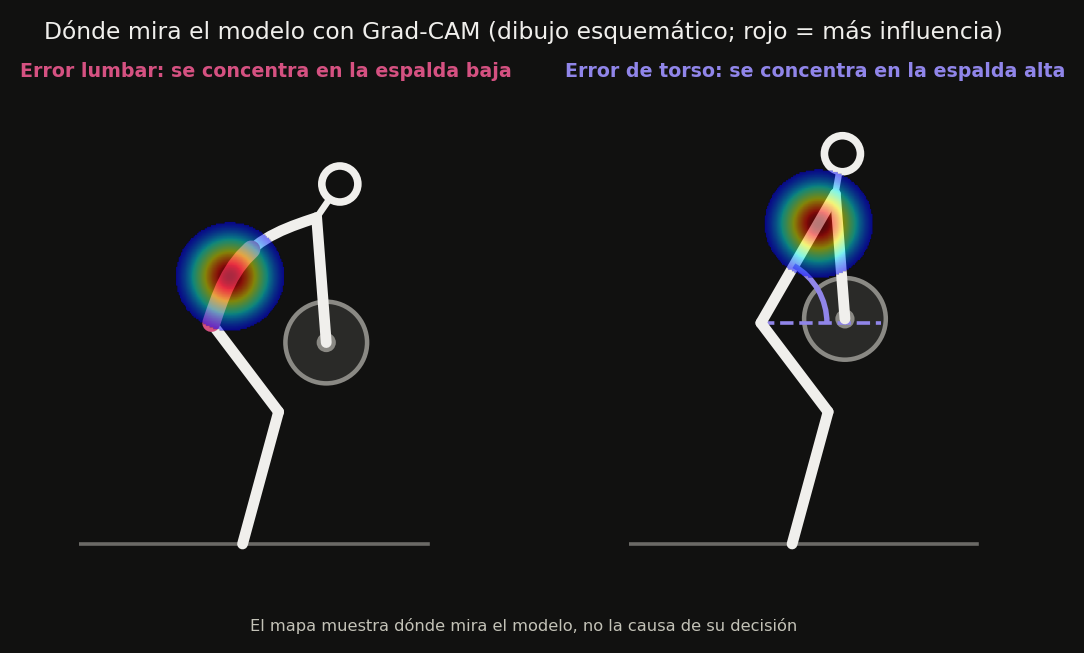

,Error,Zona,Pct_mapa,Pct_area,Veces_sobre_area
0,Lumbar,brazos y barra,4.320000,10.45,0.41
1,Lumbar,cabeza,0.350000,0.51,0.67
2,Lumbar,espalda alta,5.210000,3.72,1.40
3,Lumbar,espalda baja,14.920000,3.72,4.01
4,Lumbar,piernas,11.100000,11.05,1.00
5,Lumbar,resto de la imagen,69.480003,73.44,0.95
6,Torso,brazos y barra,15.610000,8.22,1.90
7,Torso,cabeza,1.340000,0.98,1.36
8,Torso,espalda alta,7.690000,2.75,2.79
9,Torso,espalda baja,3.480000,2.75,1.27


,Error,Pct_mapa_en_silueta,Pct_area_silueta
0,Lumbar,55.439999,62.06
1,Torso,42.709999,34.44


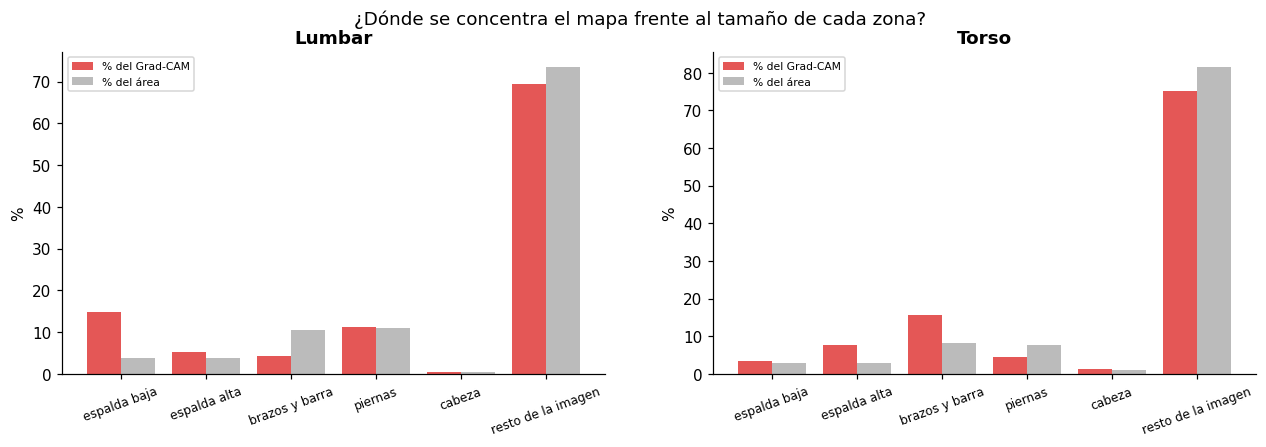

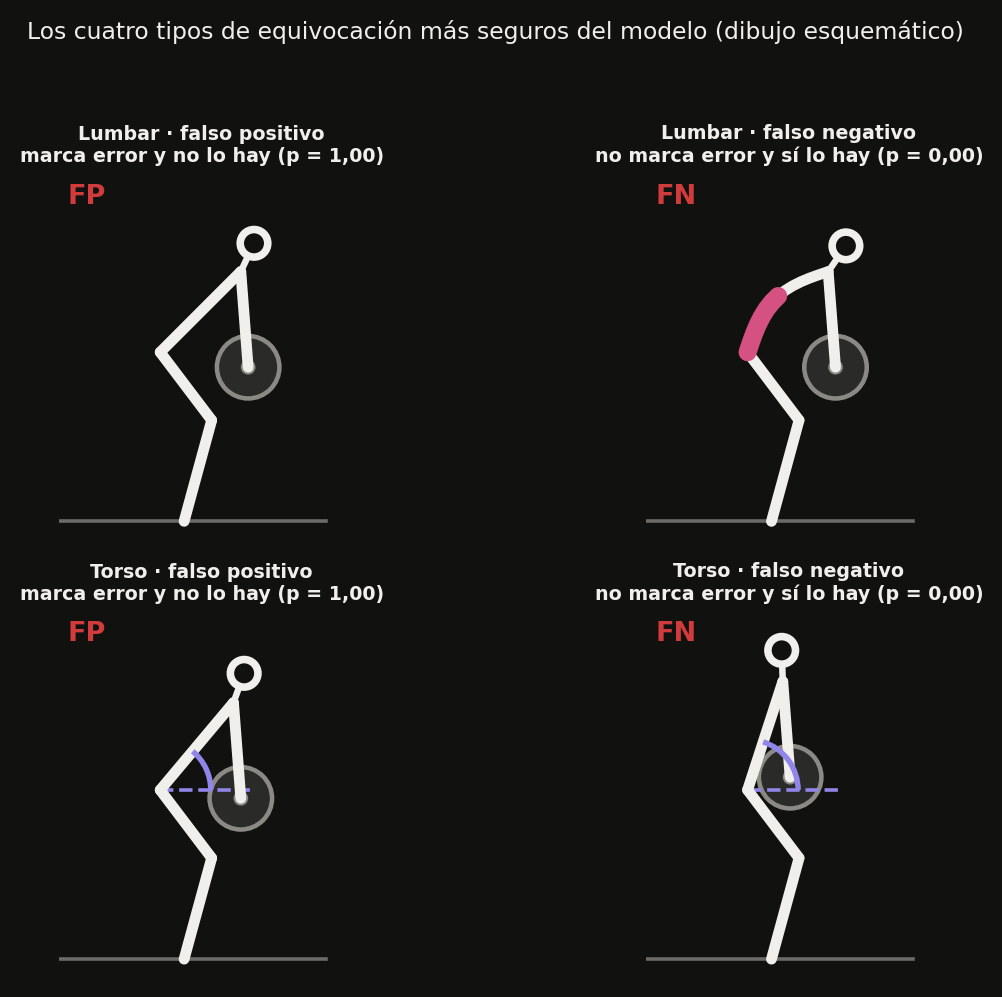

,Error,Tipo,Vista,Casos
0,Lumbar,falso positivo,de perfil,26
1,Lumbar,falso positivo,intermedia,22
2,Lumbar,falso positivo,más de frente,9
3,Lumbar,falso positivo,sin pose,4
4,Lumbar,falso negativo,de perfil,21
5,Lumbar,falso negativo,intermedia,10
6,Lumbar,falso negativo,más de frente,13
7,Lumbar,falso negativo,sin pose,2
8,Torso,falso positivo,de perfil,7
9,Torso,falso positivo,intermedia,19


── fase 6 · Grad-CAM: 2.9 min


In [27]:
ZONAS_LIN = {'brazos y barra': [(5, 7), (7, 9), (6, 8), (8, 10)], 'piernas': [(11, 13), (13, 15), (12, 14), (14, 16)],
             'cabeza': [(0, 1), (0, 2), (1, 3), (2, 4)]}
ZONAS = ['espalda baja', 'espalda alta', 'brazos y barra', 'piernas', 'cabeza', 'resto de la imagen']


def mascaras(i, res):
    """Máscaras de las zonas del cuerpo en el recorte (líneas gruesas entre puntos de la pose)."""
    k = kp_en_recorte(i, REC, res); v = k[:, 2] > UMB_KP; g = max(4, int(.09 * res)); out = {}
    hom, cad = (k[5, :2] + k[6, :2]) / 2, (k[11, :2] + k[12, :2]) / 2; mid = (hom + cad) / 2
    lin = lambda m, a, b: cv2.line(m, tuple(int(t) for t in a), tuple(int(t) for t in b), 1, g)
    for z in ZONAS[:-1]:
        m = np.zeros((res, res), np.uint8)
        if z in ('espalda baja', 'espalda alta'):
            if v[[5, 6, 11, 12]].all():
                lin(m, cad, mid) if z == 'espalda baja' else lin(m, mid, hom)
        else:
            for a, b in ZONAS_LIN[z]:
                if v[a] and v[b]:
                    lin(m, k[a, :2], k[b, :2])
        out[z] = m.astype(bool)
    out['resto de la imagen'] = ~np.any(list(out.values()), 0)
    return out


def mascara_cuerpo(i, res):
    """Silueta aproximada: casco convexo de los puntos visibles, un poco ampliado."""
    k = kp_en_recorte(i, REC, res); v = k[:, 2] > UMB_KP; m = np.zeros((res, res), np.uint8); g = max(3, int(.06 * res))
    if v.sum() >= 3:
        cv2.fillConvexPoly(m, cv2.convexHull(k[v, :2].astype(np.int32)), 1)
        m = cv2.dilate(m, np.ones((g, g), np.uint8))
    return m.astype(bool)


def gradcam(m, x, j, dev):
    x = x.to(dev)
    with torch.enable_grad():
        f = m.red.forward_features(m.prep(x)); f.retain_grad()
        z = m.cab(m.red.forward_head(f)); m.zero_grad(); z[:, j].sum().backward()
    cam = torch.relu((f.grad.mean((2, 3), keepdim=True) * f).sum(1)).detach()
    return cam.cpu().numpy()


def foto_cam(i, j, mods, res, dev):
    """Foto y mapa de Grad-CAM: promedio de los mapas de las semillas, cada uno normalizado a su máximo."""
    x = torch.from_numpy(decodificar(CROPS[REC][i], res).copy()).permute(2, 0, 1)[None]; mapas = []
    for mm in mods:
        mp = cv2.resize(gradcam(mm, x, j, dev)[0], (res, res)); mapas.append(mp / (mp.max() + 1e-8))
    return x[0].permute(1, 2, 0).numpy(), np.mean(mapas, 0)


with Etapa('fase 6 · Grad-CAM'):
    dev = DEVS[0]; res = FIN[0]['res']
    MODS = [cargar(ruta_pesos(c), c['timm'], c.get('drop_path', 0), dev) for c in FIN]
    POS_TE = {i: k for k, i in enumerate(ITE)}           # foto → fila de P_TEST (probabilidad del ensamble)
    with Seguro('Grad-CAM'):
        fig, ax = plt.subplots(2, 6, figsize=(18, 6.6))
        for j, e in enumerate(ERR):
            mt = (S[ITE, j] == 'test') & (Y[ITE, j] == 1); cand = ITE[mt][np.argsort(-P_TEST[mt, j])]
            for c in range(6):
                ax[j, c].axis('off')
                if c < len(cand):
                    im_, mp = foto_cam(cand[c], j, MODS, res, dev)
                    ax[j, c].imshow(im_); ax[j, c].imshow(mp, cmap='jet', alpha=.45)
                    ax[j, c].set_title(f'{NOMBRE_ERR[e]} · p = {P_TEST[POS_TE[cand[c]], j]:.2f}', fontsize=9)
        fig.suptitle('Grad-CAM en errores reales del conjunto de prueba (rojo = más influencia) · promedio de las semillas'); guardar_fig(fig, 'fig09_gradcam')
    with Seguro('Atención por zona'):
        filas_z, filas_c = [], []
        for j, e in enumerate(ERR):
            mt = (S[ITE, j] == 'test') & (Y[ITE, j] == 1)
            for i in ITE[mt]:
                _, mp = foto_cam(i, j, MODS, res, dev); tot = mp.sum() + 1e-8
                for z, mk in mascaras(i, res).items():
                    filas_z.append(dict(Error=NOMBRE_ERR[e], Zona=z, Pct_mapa=100 * mp[mk].sum() / tot, Pct_area=100 * mk.mean()))
                mk = mascara_cuerpo(i, res)
                filas_c.append(dict(Error=NOMBRE_ERR[e], Pct_mapa_en_silueta=100 * mp[mk].sum() / tot, Pct_area_silueta=100 * mk.mean()))
        T_ZON = pd.DataFrame(filas_z).groupby(['Error', 'Zona'], as_index=False).mean()
        T_ZON['Veces_sobre_area'] = T_ZON.Pct_mapa / T_ZON.Pct_area.clip(lower=.1)
        guardar_tabla(T_ZON.round(2), 'zonas_gradcam')
        T_SIL = pd.DataFrame(filas_c).groupby('Error', as_index=False).mean(); guardar_tabla(T_SIL.round(2), 'silueta_gradcam')
    with Seguro('Figura zonas'):
        fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
        for j, e in enumerate(ERR):
            d = T_ZON[T_ZON.Error == NOMBRE_ERR[e]].set_index('Zona'); xx = np.arange(len(ZONAS))
            ax[j].bar(xx - .2, [d.Pct_mapa.get(z, np.nan) for z in ZONAS], .4, label='% del Grad-CAM', color='#E45756')
            ax[j].bar(xx + .2, [d.Pct_area.get(z, np.nan) for z in ZONAS], .4, label='% del área', color='#bbbbbb')
            ax[j].set_xticks(xx); ax[j].set_xticklabels(ZONAS, rotation=20, fontsize=8); ax[j].set_ylabel('%'); ax[j].set_title(NOMBRE_ERR[e]); ax[j].legend(fontsize=7)
        fig.suptitle('¿Dónde se concentra el mapa frente al tamaño de cada zona?'); guardar_fig(fig, 'fig10_zonas')
    with Seguro('Galería de errores'):
        fig, ax = plt.subplots(4, 5, figsize=(15, 13)); fila = 0; filas_e = []
        for j, e in enumerate(ERR):
            mt = S[ITE, j] == 'test'; idx, p, y = ITE[mt], P_TEST[mt, j], Y[ITE][mt, j]; t = UMB[e]
            fp_ = idx[(p >= t) & (y == 0)][np.argsort(-p[(p >= t) & (y == 0)])]; fn_ = idx[(p < t) & (y == 1)][np.argsort(p[(p < t) & (y == 1)])]
            for tipo_, lista in (('falso positivo', fp_), ('falso negativo', fn_)):
                filas_e += [dict(Error=NOMBRE_ERR[e], Tipo=tipo_, Vista=v_, Casos=int((VISTA[lista] == v_).sum())) for v_ in ('de perfil', 'intermedia', 'más de frente', 'sin pose')]
                for c in range(5):
                    a = ax[fila, c]; a.axis('off')
                    if c < len(lista):
                        im_, mp = foto_cam(lista[c], j, MODS, res, dev)
                        a.imshow(im_); a.imshow(mp, cmap='jet', alpha=.4)
                        a.set_title(f'{NOMBRE_ERR[e]} · {tipo_}\np = {P_TEST[POS_TE[lista[c]], j]:.2f} · {VISTA[lista[c]]}', fontsize=8)
                fila += 1
        fig.suptitle('Los errores más seguros del modelo en el conjunto de prueba (con su Grad-CAM y el ángulo de la cámara)'); guardar_fig(fig, 'fig11_errores')
        T_ERRV = pd.DataFrame(filas_e); guardar_tabla(T_ERRV, 'errores_por_vista')
    del MODS; torch.cuda.empty_cache()

## Velocidad de cada red

Milisegundos por foto (solo la CNN, lote de 1) en la T4 y en la CPU de Kaggle, frente a la AP de prueba. El ensamble cuesta tantas veces como semillas.

,Red,Dispositivo,ms_por_foto,Parametros_M
0,ResNet-18,GPU T4,3.2,11.3
1,ResNet-18,CPU,44.1,11.3
2,ResNet-50,GPU T4,8.2,24.0
3,ResNet-50,CPU,84.1,24.0
4,ConvNeXt-S,GPU T4,14.8,49.7
5,ConvNeXt-S,CPU,141.6,49.7


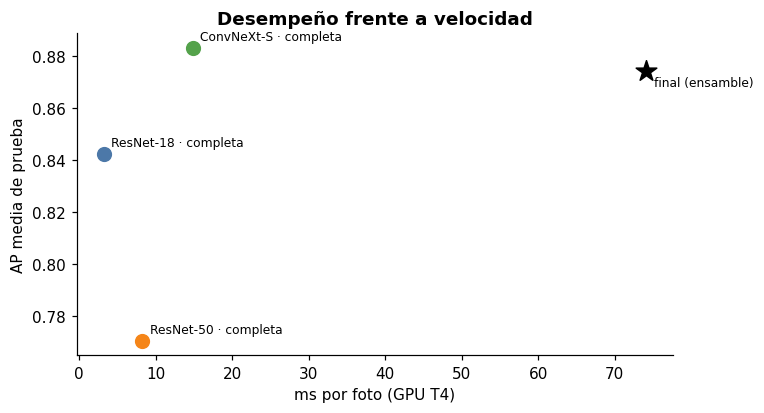

In [28]:
with Seguro('Velocidad'):
    filas = []
    for r in REDES:
        mm = Modelo(REDES[r], preentrenada=False).eval(); lado = RES_RED
        for d_ in ([DEVS[0], 'cpu'] if DEVS[0] != 'cpu' else ['cpu']):
            mm = mm.to(d_); x = torch.randint(0, 255, (1, 3, lado, lado), dtype=torch.uint8).to(d_)
            with torch.no_grad(), torch.autocast('cuda', torch.float16, enabled=d_ != 'cpu'):
                for _ in range(3): mm(x)
                if d_ != 'cpu': torch.cuda.synchronize()
                t = time.time(); n = 5 if d_ == 'cpu' else 30
                for _ in range(n): mm(x)
                if d_ != 'cpu': torch.cuda.synchronize()
            filas.append(dict(Red=NOMBRE_RED[r], Dispositivo='GPU T4' if d_ != 'cpu' else 'CPU', ms_por_foto=1000 * (time.time() - t) / n,
                              Parametros_M=sum(p.numel() for p in mm.parameters()) / 1e6))
    T_VEL = pd.DataFrame(filas); guardar_tabla(T_VEL.round(1), 'velocidad')
    fig, ax = plt.subplots(figsize=(7, 3.8)); disp = 'GPU T4' if (T_VEL.Dispositivo == 'GPU T4').any() else 'CPU'
    for r in REDES:
        er = T_GRID[T_GRID.red == r].sort_values('AP_val', ascending=False).estrategia.iloc[0]
        apt = TABLA[TABLA.Modelo == f'{NOMBRE_RED[r]} · {er}'].AP.mean(); ms = T_VEL[(T_VEL.Red == NOMBRE_RED[r]) & (T_VEL.Dispositivo == disp)].ms_por_foto.iloc[0]
        ax.scatter(ms, apt, s=80, color=COLR[r]); ax.annotate(f'{NOMBRE_RED[r]} · {er}', (ms, apt), fontsize=8, xytext=(5, 5), textcoords='offset points')
    msf = T_VEL[(T_VEL.Red == NOMBRE_RED[rg]) & (T_VEL.Dispositivo == disp)].ms_por_foto.iloc[0] * len(FIN)
    apf = TABLA[TABLA.Modelo == NOMBRE_FINAL].AP.mean()
    ax.scatter(msf, apf, marker='*', s=200, color='k'); ax.annotate('final (ensamble)', (msf, apf), fontsize=8, xytext=(5, -10), textcoords='offset points')
    ax.set_xlabel(f'ms por foto ({disp})'); ax.set_ylabel('AP media de prueba'); ax.set_title('Desempeño frente a velocidad'); guardar_fig(fig, 'fig12_velocidad')

## Equipo, tiempos e hiperparámetros usados

,Recurso,Valor
0,GPU,"Tesla T4, Tesla T4"
1,CPU_nucleos,4
2,Python,3.13.15
3,PyTorch,2.11.0+cu128
4,timm,1.0.29
5,Pose,rtmpose
6,Proveedor_pose,"CUDAExecutionProvider, CUDAExecutionProvider"
7,Horas,7.12
8,Corridas,68
9,Minutos_GPU,732.4


,corrida,gpu,inicio_h,minutos,red,estrategia,resolucion,entrenables_M,mejor_epoca,ap_val
0,resnet50_completa_completa_s100,cuda:0,0.463,7.955,resnet50,completa,224,24.033,4,0.698
1,resnet50_completa_completa_s101,cuda:1,0.463,11.267,resnet50,completa,224,24.033,7,0.694
2,resnet50_completa_persona_s100,cuda:0,0.595,10.410,resnet50,completa,224,24.033,8,0.689
3,resnet50_completa_persona_s101,cuda:1,0.651,10.800,resnet50,completa,224,24.033,8,0.685
4,resnet50_completa_tronco_s100,cuda:0,0.769,7.484,resnet50,completa,224,24.033,4,0.722
...,...,...,...,...,...,...,...,...,...,...
63,convnext_s_parcial_tronco_pesosalt_s2,cuda:0,6.441,6.304,convnext_s,parcial,224,15.670,3,0.656
64,convnext_s_parcial_tronco_pesosalt_s1,cuda:1,6.418,8.265,convnext_s,parcial,224,15.670,5,0.663
65,convnext_s_completa_tronco_pesosalt_s0,cuda:0,6.546,10.402,convnext_s,completa,224,49.652,3,0.872
66,convnext_s_completa_tronco_pesosalt_s1,cuda:1,6.556,15.456,convnext_s,completa,224,49.652,5,0.882


,Red,lr_red,lr_cabeza,weight_decay,lote,epocas_max,paciencia,calendario,perdida,ema,epocas,drop_path
0,ResNet-18,0.00030,0.001,0.05,64.0,10.0,3.0,calentamiento + coseno,BCE con logits + peso de clase,NaN,NaN,NaN
1,ResNet-50,0.00020,0.001,0.05,64.0,10.0,3.0,calentamiento + coseno,BCE con logits + peso de clase,NaN,NaN,NaN
2,ConvNeXt-S,0.00008,0.001,0.05,64.0,10.0,3.0,calentamiento + coseno,BCE con logits + peso de clase,NaN,NaN,NaN
3,configuración final,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,14.0,0.1


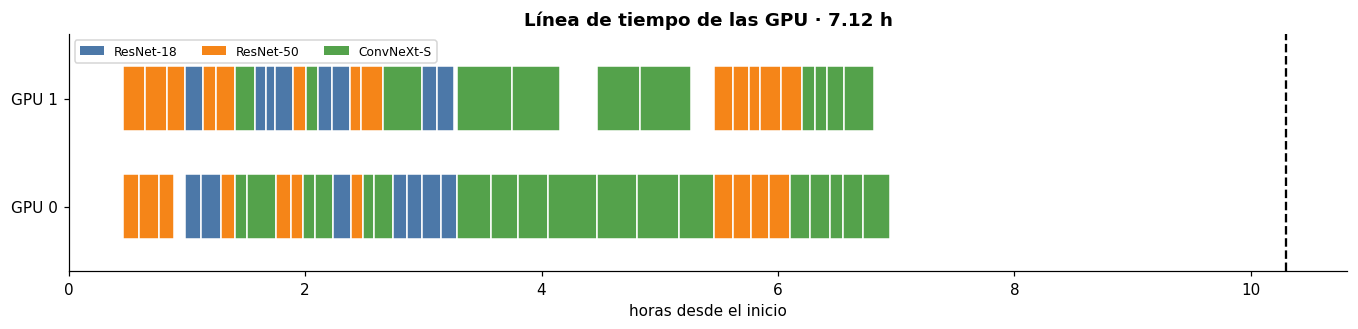

In [29]:
with Seguro('Equipo y tiempos'):
    EQUIPO = dict(GPU=', '.join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())) or 'ninguna', CPU_nucleos=os.cpu_count(),
                  Python=platform.python_version(), PyTorch=torch.__version__, timm=timm.__version__, Pose=METODO_POSE, Proveedor_pose=', '.join(PROVEEDOR_POSE),
                  Horas=round(horas(), 2), Corridas=len(RES), Minutos_GPU=round(sum(r['minutos'] for r in RES.values()), 1))
    guardar_tabla(pd.DataFrame([dict(Recurso=k, Valor=v) for k, v in EQUIPO.items()]), 'equipo')
    TR = pd.DataFrame([dict(corrida=n, gpu=r['gpu'], inicio_h=r['inicio_h'], minutos=r['minutos'], red=r['cfg']['red'], estrategia=r['cfg']['estrategia'],
                            resolucion=r['cfg']['res'], entrenables_M=r['entrenables'] / 1e6, mejor_epoca=r['mejor_epoca'], ap_val=r['ap_val'])
                       for n, r in RES.items()])
    guardar_tabla(TR.round(3), 'corridas')
    guardar_tabla(pd.DataFrame([dict(Red=NOMBRE_RED[r], lr_red=LR_RED[r], lr_cabeza=1e-3, weight_decay=.05, lote=64, epocas_max=EPOCAS_BASE,
                                     paciencia=3, calendario='calentamiento + coseno', perdida='BCE con logits + peso de clase')
                                for r in REDES] + [dict(Red='configuración final', **FINAL)]), 'hiperparametros')
    fig, ax = plt.subplots(figsize=(15, 2.8))
    for r in TR.itertuples():
        g_ = DEVS.index(r.gpu) if r.gpu in DEVS else 0
        ax.barh(g_, r.minutos / 60, left=r.inicio_h, color=COLR.get(r.red, 'gray'), edgecolor='white', height=.6)
    for k_, v_ in COLR.items(): ax.barh(-5, 0, color=v_, label=NOMBRE_RED[k_])
    ax.axvline(CORTE, color='k', ls='--'); ax.set_ylim(-.6, len(DEVS) - .4); ax.set_yticks(range(len(DEVS))); ax.set_yticklabels([f'GPU {g_}' for g_ in range(len(DEVS))])
    ax.set_xlabel('horas desde el inicio'); ax.legend(fontsize=8, ncol=3); ax.set_title(f'Línea de tiempo de las GPU · {horas():.2f} h'); guardar_fig(fig, 'fig13_gpu')

# Conclusiones

1. ConvNeXt-S fue el modelo con mejor resultado, usando ajuste completo, recorte del tronco y un ensamble de semillas. En la prueba obtuvo una AP de 0,93 para errores lumbares y 0,82 para errores del torso.

2. Ajustar toda la red y partir de pesos de ImageNet dio mejores resultados que congelar capas o iniciar con pesos aleatorios. ConvNeXt-S superó a ResNet-50, aunque frente a ResNet-18 la ventaja solo fue clara en errores lumbares.

3. Los ajustes adicionales de entrenamiento mejoraron muy poco los resultados y no mostraron una diferencia importante en la prueba.

4. Con Grad-CAM, en el error lumbar la espalda baja recibió 4 veces la parte del mapa que le corresponde por su área, y en el de torso la espalda alta recibió 2,8 veces. Aun así, el 69 % y el 75 % del mapa quedó fuera de las zonas medidas, así que esto muestra dónde mira el modelo y no la causa de sus decisiones.

5. Aunque los resultados son buenos, deben tomarse con cuidado porque se utilizó varias veces la validación para elegir el modelo y se probaron pocas semillas. Hace falta evaluar con más datos para confirmar su rendimiento.

## Guardar los resultados para el notebook 2

Se guardaron en `outputs/` los pesos del modelo final, los umbrales, las predicciones, el índice de fotos y los recortes. El notebook 2 los carga para probar este mismo modelo con videos propios y con cambios en las fotos, sin volver a entrenar. Las figuras de `resultados_remo.zip` incluyen fotos de Fitness-AQA, por eso no se suben al repositorio.

In [31]:
# ============================================================
# Guardar resultados y zip
# ============================================================
PV = OUT / 'para_validaciones'
pd.DataFrame(dict(id=IDS, clip=CLIP, split=SPLIT, s_lumbar=S[:, 0], s_torso=S[:, 1], y_lumbar=Y[:, 0], y_torso=Y[:, 1], razon=RAZON, vista=VISTA)).to_csv(PV / 'indice.csv', index=False)
np.savez_compressed(PV / 'miniaturas.npz', T=MINI)
pickle.dump(dict(val=[CROPS[REC][i] for i in IVA], test=[CROPS[REC][i] for i in ITE]), open(PV / 'recortes_val_test.pkl', 'wb'), protocol=4)
R18 = hechas(F2[('resnet18', 'completa')])
for c in R18:                 # por si después se quiere una versión liviana, sin volver a entrenar
    shutil.copy(ruta_pesos(c), OUT / 'modelos' / f"{c['nombre']}.pt")
PRED_MOD = {}
for c in FIN + R18:
    PRED_MOD[f"val__{c['nombre']}"] = RES[c['nombre']]['P_val']
    if RES[c['nombre']]['P_test'] is not None:
        PRED_MOD[f"test__{c['nombre']}"] = RES[c['nombre']]['P_test']
np.savez_compressed(PV / 'predicciones_final.npz', ids_val=np.array(IDS)[IVA], ids_test=np.array(IDS)[ITE], P_val=P_VAL, P_test=P_TEST, **PRED_MOD)
TABLA[TABLA.Modelo == NOMBRE_FINAL].to_csv(PV / 'test_final_exacto.csv', index=False)
if 'T_REP' in globals():
    T_REP.to_csv(PV / 'test_por_repeticion_exacto.csv', index=False)
rng = np.random.default_rng(0); rq = []
for i in rng.choice(np.where(SPLIT == 'train')[0], min(300, int((SPLIT == 'train').sum())), replace=False):
    c = decodificar(CROPS[REC][i], res_f); rq.append((c.mean(), cv2.Laplacian(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()))
CONFIG = dict(prueba_local=PRUEBA, recorte=REC, red=rg, estrategia=eg, receta=FINAL, res=res_f, res_guarda=RES_GUARDA, lado_max=LADO_MAX, umb_kp=UMB_KP,
              modelos_final=[dict(nombre=c['nombre'], timm=c['timm'], drop_path=c.get('drop_path', 0)) for c in FIN],
              modelos_resnet18=[dict(nombre=c['nombre'], timm=c['timm']) for c in R18],
              umbrales_por_foto=UMB, umbrales_por_repeticion=UMB_CLIP, metodo_pose=METODO_POSE, proveedor_pose=PROVEEDOR_POSE,
              decisiones_congeladas_en=DECISION['congeladas_en'], prueba_primer_uso_en=TEST_PRIMER_USO, nombre_final=NOMBRE_FINAL,
              razon_dataset_p5_p50_p95=np.quantile(rz_tr, [.05, .5, .95]).tolist() if len(rz_tr) else [],
              cortes_vista=CORTES_V.tolist(), calidad_dataset=dict(Brillo=float(np.median([a for a, _ in rq])), Nitidez=float(np.median([b for _, b in rq])),
                                                                 Puntos_visibles=float((KP[SPLIT == 'train'][..., 2] > UMB_KP).mean())))
json.dump(limpio(CONFIG), open(PV / 'config.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
json.dump(limpio(dict(horas=horas(), config=CONFIG, notas=NOTAS, equipo=globals().get('EQUIPO', {}), tiempos=TIEMPOS,
                      corridas={n: {k: v for k, v in r.items() if not k.startswith('P_')} for n, r in RES.items()})),
          open(OUT / 'results.json', 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
zr = OUT.parent / 'resultados_remo.zip'
with zipfile.ZipFile(zr, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file() and 'modelos' not in p.parts and 'para_validaciones' not in p.parts:
            z.write(p, p.relative_to(OUT.parent))
print(f'Listo en {horas():.2f} h · {zr} ({zr.stat().st_size / 1e6:.1f} MB) · pesos en {OUT / "modelos"} · para el notebook 2 en {PV}')

Listo en 7.12 h · /kaggle/working/resultados_remo.zip (6.3 MB) · pesos en /kaggle/working/outputs/modelos · para el notebook 2 en /kaggle/working/outputs/para_validaciones
